# Caso 1 · Paso 1: línea base de un modelo de visión

**Objetivo:** entrenar (ajustar) un modelo pequeño de clasificación de imágenes y medir los números de partida
que luego se mejorarán: **precisión, tamaño, parámetros y tiempo por imagen**.

**Importante:** Se usa una arquitectura estándar ya preentrenada
(MobileNetV3-Small) y para luego ajustar al conjunto de datos (*transfer learning*). El valor del caso
está en la optimización posterior, no en inventar la red.

**Cómo usarlo en Colab**
1. Menú *Entorno de ejecución* → *Cambiar tipo de entorno de ejecución* → elige una **GPU** (T4 si aparece).
2. Ejecuta las celdas en orden (Ctrl+Enter en cada una, o *Entorno de ejecución* → *Ejecutar todo*).
3. Al final se guarda `resultados_linea_base.json` y el modelo `baseline_mobilenetv3s.pt` en el panel de archivos (icono de carpeta).

In [1]:
import time, os, json, random
import numpy as np
import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from torch.utils.data import DataLoader, Subset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo de entrenamiento:", device)
if device == "cpu":
    print("Aviso: sin GPU el entrenamiento será lento. Cambia el tipo de entorno de ejecución.")

Dispositivo de entrenamiento: cuda


## 1. Datos

Usamos **CIFAR-10** (10 clases de objetos, imágenes pequeñas) solo para armar y probar la tubería.


Parámetros que puedes ajustar:
- `TRAIN_SUBSET`: cuántas imágenes de entrenamiento usar (menos = más rápido).
- `EPOCHS`: cuántas pasadas completas por esos datos.
- `IMG_SIZE`: tamaño al que se redimensionan las imágenes.

In [2]:
IMG_SIZE = 64
TRAIN_SUBSET = 20000
EPOCHS = 3
BATCH = 128

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

tf_train = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
tf_test = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_full = datasets.CIFAR10("./data", train=True, download=True, transform=tf_train)
test_set = datasets.CIFAR10("./data", train=False, download=True, transform=tf_test)

g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(train_full), generator=g)[:TRAIN_SUBSET].tolist()
train_set = Subset(train_full, idx)

train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True, num_workers=2)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)

print(f"Entrenamiento: {len(train_set)} imágenes | Prueba: {len(test_set)} imágenes")

100%|██████████| 170M/170M [42:29<00:00, 66.9kB/s]


Entrenamiento: 20000 imágenes | Prueba: 10000 imágenes


## 2. Modelo (preentrenado)

Cargamos MobileNetV3-Small con pesos entrenados en ImageNet y cambiamos solo la última capa
para que dé 10 clases en lugar de 1000.

In [3]:
model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
in_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_features, 10)
model = model.to(device)
print("Modelo listo. Última capa:", model.classifier[3])

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 114MB/s]


Modelo listo. Última capa: Linear(in_features=1024, out_features=10, bias=True)


## 3. Entrenamiento (ajuste fino)

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

def evaluate(m, loader, dev):
    m.eval()
    correct, total = 0, 0
    with torch.inference_mode():
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            correct += (m(x).argmax(1) == y).sum().item()
            total += y.size(0)
    return correct / total

for epoch in range(EPOCHS):
    model.train()
    t0 = time.time()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * y.size(0)
    acc = evaluate(model, test_loader, device)
    print(f"Época {epoch+1}/{EPOCHS} | pérdida {running/len(train_set):.3f} | "
          f"precisión en prueba {acc*100:.2f}% | {time.time()-t0:.0f} s")

Época 1/3 | pérdida 1.044 | precisión en prueba 63.43% | 17 s
Época 2/3 | pérdida 0.593 | precisión en prueba 73.85% | 14 s
Época 3/3 | pérdida 0.445 | precisión en prueba 78.23% | 14 s


## 4. Medir la línea base

Medimos cuatro cosas:
- **Precisión** en las 10,000 imágenes de prueba.
- **Parámetros** y **tamaño** del modelo guardado en disco (MB).
- **Latencia** por imagen en CPU con un solo hilo, para parecerse un poco más a un dispositivo pequeño.

**Ojo:** la latencia de Colab no es la de un Raspberry Pi, donde se planea probar el modelo optimizado. Estos números sirven para comparar
*versiones del modelo entre sí en la misma máquina*. Cuando tengamos el modelo optimizado,
repetiremos la medición en la Pi con el mismo procedimiento. La **memoria RAM** también la mediremos allá.

In [5]:
def model_size_mb(m, path):
    torch.save(m.state_dict(), path)
    return os.path.getsize(path) / 1e6

def count_params(m):
    return sum(p.numel() for p in m.parameters())

def latency_cpu_ms(m, runs=200, warmup=30):
    m = m.to("cpu").eval()
    torch.set_num_threads(1)
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    times = []
    with torch.inference_mode():
        for _ in range(warmup):
            m(x)
        for _ in range(runs):
            t = time.perf_counter()
            m(x)
            times.append((time.perf_counter() - t) * 1000)
    return float(np.mean(times)), float(np.percentile(times, 95))

acc_final = evaluate(model, test_loader, device)
size_mb = model_size_mb(model, "baseline_mobilenetv3s.pt")
params = count_params(model)
lat_mean, lat_p95 = latency_cpu_ms(model)

results = {
    "modelo": "MobileNetV3-Small (preentrenado, ajuste fino)",
    "entrada": f"{IMG_SIZE}x{IMG_SIZE}",
    "epocas": EPOCHS,
    "imagenes_entrenamiento": TRAIN_SUBSET,
    "precision_pct": round(acc_final * 100, 2),
    "parametros": params,
    "tamano_MB": round(size_mb, 2),
    "latencia_ms_media_1hilo_CPU": round(lat_mean, 2),
    "latencia_ms_p95_1hilo_CPU": round(lat_p95, 2),
}

print(json.dumps(results, indent=2, ensure_ascii=False))
with open("resultados_linea_base.json", "w") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print("\nGuardado: resultados_linea_base.json y baseline_mobilenetv3s.pt")

{
  "modelo": "MobileNetV3-Small (preentrenado, ajuste fino)",
  "entrada": "64x64",
  "epocas": 3,
  "imagenes_entrenamiento": 20000,
  "precision_pct": 78.23,
  "parametros": 1528106,
  "tamano_MB": 6.25,
  "latencia_ms_media_1hilo_CPU": 5.98,
  "latencia_ms_p95_1hilo_CPU": 7.34
}

Guardado: resultados_linea_base.json y baseline_mobilenetv3s.pt


## Qué sigue (paso 2)

Con estos números como fila de partida, aplicaremos y mediremos, una por una:
1. **Cuantización** a enteros de 8 bits.
2. **Poda** (quitar pesos poco útiles).
3. Una **arquitectura más ligera**.
4. **Búsqueda evolutiva multiobjetivo** sobre esas decisiones, para obtener el frente de las mejores combinaciones entre precisión, tamaño y latencia.

Antes de la cuantización decidiremos con qué herramienta exportar para la Raspberry Pi
(por ejemplo ONNX o TFLite), porque instalar PyTorch completo en una Pi 3 puede ser complicado.

**Anotar aquí los números de partida** (para compararlos después):
- Precisión: 78.23
- Tamaño (MB): 6.25
- Latencia media (ms): 7.54

In [6]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxruntime"], check=True)
import onnx, onnxruntime
print("onnx", onnx.__version__, "| onnxruntime", onnxruntime.__version__)

onnx 1.23.2 | onnxruntime 1.31.1


In [7]:
import os, time, json, random
import numpy as np
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v3_small
import onnxruntime as ort
from onnxruntime.quantization import (quantize_dynamic, quantize_static, QuantType,
                                      QuantFormat, CalibrationDataReader)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

IMG_SIZE = 64          # debe coincidir con el paso 1
EVAL_N = 10000         # imágenes de prueba para medir precisión (bajar a 5000 para ir más rápido)
CALIB_N = 200          # imágenes para calibrar la cuantización estática

BASE_PT = "baseline_mobilenetv3s.pt"
if not os.path.exists(BASE_PT):
    from google.colab import files
    print("No encuentro", BASE_PT, "-> súbelo ahora:")
    files.upload()

model = mobilenet_v3_small(weights=None)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, 10)
model.load_state_dict(torch.load(BASE_PT, map_location="cpu"))
model.eval()
print("Modelo base cargado.")

Modelo base cargado.


In [8]:
def n_params(m):
    return sum(p.numel() for p in m.parameters())

total = n_params(model)
print(f"Total: {total:,} parámetros")
print(f"  features (convoluciones): {n_params(model.features):,}  ({n_params(model.features)/total*100:.1f}%)")
print(f"  classifier[0] Linear {model.classifier[0].in_features}->{model.classifier[0].out_features}: "
      f"{n_params(model.classifier[0]):,}  ({n_params(model.classifier[0])/total*100:.1f}%)")
print(f"  classifier[3] Linear {model.classifier[3].in_features}->{model.classifier[3].out_features}: "
      f"{n_params(model.classifier[3]):,}  ({n_params(model.classifier[3])/total*100:.1f}%)")

Total: 1,528,106 parámetros
  features (convoluciones): 927,008  (60.7%)
  classifier[0] Linear 576->1024: 590,848  (38.7%)
  classifier[3] Linear 1024->10: 10,250  (0.7%)


In [9]:
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
tf = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.ToTensor(), transforms.Normalize(mean, std)])

test_set = datasets.CIFAR10("./data", train=False, download=True, transform=tf)
train_set = datasets.CIFAR10("./data", train=True, download=True, transform=tf)

def to_numpy(dataset, indices):
    xs, ys = [], []
    for i in indices:
        x, y = dataset[i]
        xs.append(x.numpy())
        ys.append(y)
    return np.stack(xs).astype(np.float32), np.array(ys, dtype=np.int64)

X_test, Y_test = to_numpy(test_set, range(EVAL_N))
rng = np.random.RandomState(SEED)
calib_idx = rng.choice(len(train_set), CALIB_N, replace=False)
X_calib, _ = to_numpy(train_set, calib_idx)
print("Prueba:", X_test.shape, "| Calibración:", X_calib.shape)

# Subconjunto para copiar a la Raspberry Pi (sin necesitar PyTorch allá)
np.save("pi_test_x.npy", X_test[:500])
np.save("pi_test_y.npy", Y_test[:500])
print("Guardados pi_test_x.npy y pi_test_y.npy (500 imágenes)")

Prueba: (10000, 3, 64, 64) | Calibración: (200, 3, 64, 64)
Guardados pi_test_x.npy y pi_test_y.npy (500 imágenes)


In [10]:
ONNX_FP32 = "mobilenetv3s_fp32.onnx"
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
base_kwargs = dict(input_names=["input"], output_names=["logits"],
                   dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}})

attempts = [dict(dynamo=False, opset_version=17), dict(opset_version=17), dict(dynamo=True)]
last_err = None
for extra in attempts:
    try:
        torch.onnx.export(model, dummy, ONNX_FP32, **base_kwargs, **extra)
        print("Exportado con:", extra)
        last_err = None
        break
    except Exception as e:
        last_err = e
        print("Intento fallido con", extra, "->", type(e).__name__)
if last_err is not None:
    raise last_err

onnx.checker.check_model(onnx.load(ONNX_FP32))
print("Modelo ONNX válido.")

/tmp/ipykernel_443/594932133.py:10: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, ONNX_FP32, **base_kwargs, **extra)


Exportado con: {'dynamo': False, 'opset_version': 17}
Modelo ONNX válido.


In [11]:
def make_session(path, threads=1):
    so = ort.SessionOptions()
    so.intra_op_num_threads = threads
    so.inter_op_num_threads = 1
    return ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])

def size_mb(path):
    return os.path.getsize(path) / 1e6

def eval_acc(path, X, Y):
    sess = make_session(path)
    inp = sess.get_inputs()[0]
    fixed_batch = isinstance(inp.shape[0], int)
    bs = inp.shape[0] if fixed_batch else 100
    correct = 0
    for i in range(0, len(X), bs):
        xb = X[i:i + bs]
        if fixed_batch and len(xb) != bs:
            break
        out = sess.run(None, {inp.name: xb})[0]
        correct += int((out.argmax(1) == Y[i:i + len(xb)]).sum())
    n = (len(X) // bs) * bs if fixed_batch else len(X)
    return correct / n

def latency_ms(path, runs=200, warmup=30, threads=1):
    sess = make_session(path, threads)
    inp = sess.get_inputs()[0]
    x = X_test[:1].astype(np.float32)
    for _ in range(warmup):
        sess.run(None, {inp.name: x})
    times = []
    for _ in range(runs):
        t = time.perf_counter()
        sess.run(None, {inp.name: x})
        times.append((time.perf_counter() - t) * 1000)
    return float(np.mean(times)), float(np.percentile(times, 95))

# Comprobación: ONNX debe dar prácticamente lo mismo que PyTorch
sess = make_session(ONNX_FP32)
inp_name = sess.get_inputs()[0].name
with torch.inference_mode():
    ref = model(torch.from_numpy(X_test[:16])).numpy()
onx = sess.run(None, {inp_name: X_test[:16]})[0]
print("Diferencia máxima PyTorch vs ONNX:", float(np.abs(ref - onx).max()))

Diferencia máxima PyTorch vs ONNX: 1.811981201171875e-05


In [12]:
ONNX_DYN = "mobilenetv3s_dynamic_int8.onnx"
ONNX_STA = "mobilenetv3s_static_int8.onnx"

# --- Dinámica ---
dyn_ok = False
try:
    quantize_dynamic(ONNX_FP32, ONNX_DYN, weight_type=QuantType.QInt8)
    make_session(ONNX_DYN)           # comprobar que se puede ejecutar
    dyn_ok = True
    print("Cuantización dinámica: OK")
except Exception as e:
    print("Cuantización dinámica no disponible para este modelo ->", type(e).__name__, str(e)[:150])

# --- Estática ---
class CalibReader(CalibrationDataReader):
    def __init__(self, X, input_name):
        self.items = iter([{input_name: X[i:i + 1]} for i in range(len(X))])
    def get_next(self):
        return next(self.items, None)

src = ONNX_FP32
try:
    from onnxruntime.quantization.shape_inference import quant_pre_process
    quant_pre_process(ONNX_FP32, "mobilenetv3s_prep.onnx")
    src = "mobilenetv3s_prep.onnx"
except Exception as e:
    print("Preprocesado omitido ->", type(e).__name__)

sta_ok = False
try:
    quantize_static(src, ONNX_STA, CalibReader(X_calib, inp_name),
                    quant_format=QuantFormat.QDQ, per_channel=True,
                    weight_type=QuantType.QInt8, activation_type=QuantType.QUInt8)
    make_session(ONNX_STA)
    sta_ok = True
    print("Cuantización estática: OK")
except Exception as e:
    print("Cuantización estática falló ->", type(e).__name__, str(e)[:200])

Cuantización dinámica: OK
Cuantización estática: OK


In [13]:
rows = []

# Fila de referencia del paso 1 (PyTorch), si existe el JSON
if os.path.exists("resultados_linea_base.json"):
    b = json.load(open("resultados_linea_base.json"))
    rows.append({"version": "Paso 1: PyTorch FP32 (referencia)",
                 "precision_pct": b["precision_pct"], "tamano_MB": b["tamano_MB"],
                 "latencia_ms_media": b["latencia_ms_media_1hilo_CPU"],
                 "latencia_ms_p95": b["latencia_ms_p95_1hilo_CPU"]})

candidates = [("ONNX FP32", ONNX_FP32, True),
              ("ONNX dinámica INT8", ONNX_DYN, dyn_ok),
              ("ONNX estática INT8 (QDQ)", ONNX_STA, sta_ok)]

for name, path, ok in candidates:
    if not ok:
        rows.append({"version": name, "precision_pct": None, "tamano_MB": None,
                     "latencia_ms_media": None, "latencia_ms_p95": None})
        continue
    acc = eval_acc(path, X_test, Y_test)
    lat_m, lat_p = latency_ms(path)
    rows.append({"version": name, "precision_pct": round(acc * 100, 2),
                 "tamano_MB": round(size_mb(path), 2),
                 "latencia_ms_media": round(lat_m, 2), "latencia_ms_p95": round(lat_p, 2)})

import pandas as pd
df = pd.DataFrame(rows)
print(df.to_string(index=False))
df.to_csv("resultados_paso2.csv", index=False)
json.dump(rows, open("resultados_paso2.json", "w"), indent=2, ensure_ascii=False)
print("\nGuardado: resultados_paso2.csv / .json")

                          version  precision_pct  tamano_MB  latencia_ms_media  latencia_ms_p95
Paso 1: PyTorch FP32 (referencia)          78.23       6.25               5.98             7.34
                        ONNX FP32          78.23       6.12               0.69             0.79
               ONNX dinámica INT8          12.62       1.70               5.65             6.52
         ONNX estática INT8 (QDQ)          15.48       1.88               0.75             0.88

Guardado: resultados_paso2.csv / .json


In [14]:
import os, time, json, random
import numpy as np
import onnx
import onnxruntime as ort
from onnxruntime.quantization import (quantize_static, QuantType, QuantFormat,
                                      CalibrationDataReader, CalibrationMethod)
import torch
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

IMG_SIZE = 64
EVAL_N = 3000      # imágenes de prueba (menos que en el paso 2 para ir más rápido)
CALIB_N = 500      # imágenes de calibración
RUN_ENTROPY = True # el método Entropía es el más lento; poner False para omitirlo

SRC_FP32 = "mobilenetv3s_fp32.onnx"
SRC_PREP = "mobilenetv3s_prep.onnx"
assert os.path.exists(SRC_FP32), "Falta mobilenetv3s_fp32.onnx: ejecuta antes el paso 2 en esta sesión."
SRC = SRC_PREP if os.path.exists(SRC_PREP) else SRC_FP32
print("Modelo de partida:", SRC)

Modelo de partida: mobilenetv3s_prep.onnx


In [15]:
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
tf = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.ToTensor(), transforms.Normalize(mean, std)])
test_set = datasets.CIFAR10("./data", train=False, download=True, transform=tf)
train_set = datasets.CIFAR10("./data", train=True, download=True, transform=tf)

def to_numpy(dataset, indices):
    xs, ys = [], []
    for i in indices:
        x, y = dataset[i]
        xs.append(x.numpy()); ys.append(y)
    return np.stack(xs).astype(np.float32), np.array(ys, dtype=np.int64)

X_eval, Y_eval = to_numpy(test_set, range(EVAL_N))
rng = np.random.RandomState(SEED)
calib_idx = rng.choice(len(train_set), CALIB_N, replace=False)
X_calib, _ = to_numpy(train_set, calib_idx)
print("Evaluación:", X_eval.shape, "| Calibración:", X_calib.shape)

Evaluación: (3000, 3, 64, 64) | Calibración: (500, 3, 64, 64)


In [16]:
def make_session(path, threads=1):
    so = ort.SessionOptions()
    so.intra_op_num_threads = threads
    so.inter_op_num_threads = 1
    return ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])

def eval_acc(path, X, Y, bs=100):
    sess = make_session(path)
    name = sess.get_inputs()[0].name
    correct = 0
    for i in range(0, len(X), bs):
        out = sess.run(None, {name: X[i:i + bs]})[0]
        correct += int((out.argmax(1) == Y[i:i + bs]).sum())
    return correct / len(X)

def latency_ms(path, runs=100, warmup=20):
    sess = make_session(path)
    name = sess.get_inputs()[0].name
    x = X_eval[:1]
    for _ in range(warmup):
        sess.run(None, {name: x})
    t = []
    for _ in range(runs):
        s = time.perf_counter(); sess.run(None, {name: x}); t.append((time.perf_counter() - s) * 1000)
    return float(np.mean(t))

class CalibReader(CalibrationDataReader):
    def __init__(self, X, input_name):
        self.items = iter([{input_name: X[i:i + 1]} for i in range(len(X))])
    def get_next(self):
        return next(self.items, None)

INPUT_NAME = make_session(SRC).get_inputs()[0].name

# Nombres de nodos para poder excluirlos de la cuantización
graph = onnx.load(SRC).graph
conv_nodes = [n.name for n in graph.node if n.op_type == "Conv" and n.name]
gemm_nodes = [n.name for n in graph.node if n.op_type in ("Gemm", "MatMul") and n.name]
se_nodes = [n.name for n in graph.node if n.op_type == "Conv" and n.name and ("fc1" in n.name or "fc2" in n.name)]
first_conv = conv_nodes[:1]
print(f"Convoluciones: {len(conv_nodes)} | Capas lineales: {len(gemm_nodes)} | Convoluciones de squeeze-excitation: {len(se_nodes)}")
print("Primera convolución:", first_conv)
print("Capas lineales:", gemm_nodes)

Convoluciones: 52 | Capas lineales: 2 | Convoluciones de squeeze-excitation: 18
Primera convolución: ['/features/features.0/features.0.0/Conv']
Capas lineales: ['/classifier/classifier.0/Gemm', '/classifier/classifier.3/Gemm']


In [17]:
def run_config(name, **kw):
    out = f"q_{abs(hash(name)) % 10**8}.onnx"
    row = {"configuracion": name}
    try:
        t0 = time.time()
        quantize_static(SRC, out, CalibReader(X_calib, INPUT_NAME), quant_format=QuantFormat.QDQ, **kw)
        q_time = time.time() - t0
        acc = eval_acc(out, X_eval, Y_eval)
        row.update({"precision_pct": round(acc * 100, 2),
                    "tamano_MB": round(os.path.getsize(out) / 1e6, 2),
                    "latencia_ms": round(latency_ms(out), 2),
                    "seg_cuantizar": round(q_time)})
    except Exception as e:
        row.update({"precision_pct": None, "tamano_MB": None, "latencia_ms": None,
                    "error": f"{type(e).__name__}: {str(e)[:120]}"})
    print(row)
    return row

U8, S8 = QuantType.QUInt8, QuantType.QInt8
results = []

# Referencia FP32 sobre las mismas imágenes de evaluación
acc_fp32 = eval_acc(SRC_FP32, X_eval, Y_eval)
results.append({"configuracion": "FP32 (referencia)", "precision_pct": round(acc_fp32 * 100, 2),
                "tamano_MB": round(os.path.getsize(SRC_FP32) / 1e6, 2), "latencia_ms": round(latency_ms(SRC_FP32), 2)})
print(results[0])

# Comprobaciones de cordura (descartan problemas de sesión o archivos viejos)
if SRC != SRC_FP32:
    acc_src = eval_acc(SRC, X_eval, Y_eval)
    print(f"Modelo preprocesado: {acc_src*100:.2f}% | FP32: {acc_fp32*100:.2f}%")
    assert abs(acc_src - acc_fp32) < 0.01, "El preprocesado NO coincide con el FP32: borra mobilenetv3s_prep.onnx y repite el paso 2."
print("Calibración  -> media %.3f, desv %.3f, mín %.2f, máx %.2f" % (X_calib.mean(), X_calib.std(), X_calib.min(), X_calib.max()))
print("Evaluación   -> media %.3f, desv %.3f, mín %.2f, máx %.2f" % (X_eval.mean(), X_eval.std(), X_eval.min(), X_eval.max()))
print("(Ambas filas deben parecerse; si no, hay un problema con los datos de calibración.)")

# A. Reproducción del paso 2
results.append(run_config("A. actividad U8 / peso S8, por canal, MinMax",
                          per_channel=True, activation_type=U8, weight_type=S8))
# B. reduce_range (evita saturación en CPU x86 sin instrucciones VNNI)
results.append(run_config("B. como A + reduce_range",
                          per_channel=True, activation_type=U8, weight_type=S8, reduce_range=True))
# C. todo sin signo
results.append(run_config("C. actividad U8 / peso U8",
                          per_channel=True, activation_type=U8, weight_type=U8))
# D. todo con signo
results.append(run_config("D. actividad S8 / peso S8",
                          per_channel=True, activation_type=S8, weight_type=S8))
# E. calibración por percentil (ignora valores extremos)
results.append(run_config("E. como A + calibración Percentil",
                          per_channel=True, activation_type=U8, weight_type=S8,
                          calibrate_method=CalibrationMethod.Percentile))
# F. calibración por entropía
if RUN_ENTROPY:
    results.append(run_config("F. como A + calibración Entropía",
                              per_channel=True, activation_type=U8, weight_type=S8,
                              calibrate_method=CalibrationMethod.Entropy))
# G. dejar en FP32 la primera convolución y las capas lineales
results.append(run_config("G. como A, sin cuantizar 1ª conv + capas lineales",
                          per_channel=True, activation_type=U8, weight_type=S8,
                          nodes_to_exclude=first_conv + gemm_nodes))
# H. dejar en FP32 los bloques squeeze-excitation
results.append(run_config("H. como A, sin cuantizar squeeze-excitation",
                          per_channel=True, activation_type=U8, weight_type=S8,
                          nodes_to_exclude=se_nodes))
# I. combinación de lo más prometedor
results.append(run_config("I. Percentil + reduce_range + G + H",
                          per_channel=True, activation_type=U8, weight_type=S8, reduce_range=True,
                          calibrate_method=CalibrationMethod.Percentile,
                          nodes_to_exclude=first_conv + gemm_nodes + se_nodes))

{'configuracion': 'FP32 (referencia)', 'precision_pct': 78.63, 'tamano_MB': 6.12, 'latencia_ms': 0.73}
Modelo preprocesado: 78.63% | FP32: 78.63%
Calibración  -> media 0.086, desv 1.064, mín -2.12, máx 2.64
Evaluación   -> media 0.140, desv 1.083, mín -2.12, máx 2.64
(Ambas filas deben parecerse; si no, hay un problema con los datos de calibración.)
{'configuracion': 'A. actividad U8 / peso S8, por canal, MinMax', 'precision_pct': 13.9, 'tamano_MB': 1.88, 'latencia_ms': 0.75, 'seg_cuantizar': 4}
{'configuracion': 'B. como A + reduce_range', 'precision_pct': 14.47, 'tamano_MB': 1.88, 'latencia_ms': 0.76, 'seg_cuantizar': 4}


{'configuracion': 'C. actividad U8 / peso U8', 'precision_pct': 15.47, 'tamano_MB': 1.89, 'latencia_ms': 0.9, 'seg_cuantizar': 3}
{'configuracion': 'D. actividad S8 / peso S8', 'precision_pct': 14.27, 'tamano_MB': 1.88, 'latencia_ms': 3.17, 'seg_cuantizar': 4}
Finding optimal threshold for each tensor using 'percentile' algorithm ...
Number of tensors : 142
Number of histogram bins : 2048
Percentile : (0.0010000000000047748,99.999)
{'configuracion': 'E. como A + calibración Percentil', 'precision_pct': 18.77, 'tamano_MB': 1.88, 'latencia_ms': 0.79, 'seg_cuantizar': 6}
Finding optimal threshold for each tensor using 'entropy' algorithm ...
Number of tensors : 142
Number of histogram bins : 128 (The number may increase depends on the data it collects)
Number of quantized bins : 128
{'configuracion': 'F. como A + calibración Entropía', 'precision_pct': 13.9, 'tamano_MB': 1.88, 'latencia_ms': 0.72, 'seg_cuantizar': 5}
{'configuracion': 'G. como A, sin cuantizar 1ª conv + capas lineales', '

# Caso 1 · Paso 3: cuantización con búsqueda evolutiva

**Idea:** en lugar de redondear los pesos con reglas fijas, usar **optimización evolutiva** para decidir *cuánta
precisión* darle a cada capa y *dónde recortar* sus valores, buscando el mejor equilibrio entre precisión y tamaño.

**Qué hace este cuaderno (todo en PyTorch, sin ONNX)**
- **Fase A · Diagnóstico:** ¿qué rompe la precisión, los **pesos** o las **activaciones**? (los separamos).
- **Fase B · Sensibilidad:** ¿qué capas aguantan menos que les bajen la precisión?
- **Fase C · Evolución diferencial:** optimiza el umbral de recorte de cada capa a 4 bits.
- **Fase D · Multiobjetivo:** busca la mejor combinación de bits por capa (3, 4, 6 u 8) y recortes, con la **frontera**
  precisión contra tamaño.

**Importante**
- Es una **simulación**: los pesos se redondean y se vuelven a convertir a decimales para medir la precisión *como si* el
  hardware usara enteros. Muestra qué precisión se obtendría, no la velocidad ni el tamaño real en disco.
- Plegamos las capas de normalización (BatchNorm) dentro de las convoluciones, que es lo que hace cualquier exportación
  para despliegue. Se sabe que esto puede dificultar la cuantización en redes tipo MobileNet.
- Los resultados finales se miden en imágenes que **la búsqueda nunca vio**.

**Usamos una GPU** (Entorno de ejecución → Cambiar tipo de entorno de ejecución). Se va a necestar `baseline_mobilenetv3s.pt`;
si no está en la sesión, el cuaderno te pedirá subirlo. Tiempo estimado: de 15 a 40 minutos según la GPU.

In [18]:
import os, time, json, random, copy
import numpy as np
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v3_small
from torch.nn.utils.fusion import fuse_conv_bn_eval
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)
if device == "cpu":
    print("Aviso: sin GPU esto será muy lento. Cambia el tipo de entorno de ejecución.")

# ---- Parámetros que puedes ajustar ----
IMG_SIZE = 64
SEARCH_N = 1500          # imágenes que usa la búsqueda para evaluar cada candidato
CALIB_N = 500            # imágenes para calibrar activaciones (Fase A)
BITS_FOCUS = 4           # bits de peso para las Fases B y C
DE_MAXITER = 20          # generaciones de la evolución diferencial
DE_POP_MULT = 2          # individuos = DE_POP_MULT x número de capas
MO_POP = 40              # población de la búsqueda multiobjetivo
MO_GENS = 20             # generaciones de la búsqueda multiobjetivo
BIT_CHOICES = [3, 4, 6, 8]
ALPHA_MIN = 0.4          # recorte mínimo permitido (fracción del valor máximo de cada canal)

Dispositivo: cuda


In [19]:
BASE_PT = "baseline_mobilenetv3s.pt"
if not os.path.exists(BASE_PT):
    from google.colab import files
    print("Sube", BASE_PT)
    files.upload()

net = mobilenet_v3_small(weights=None)
net.classifier[3] = nn.Linear(net.classifier[3].in_features, 10)
net.load_state_dict(torch.load(BASE_PT, map_location="cpu"))
net.eval()

def fold_bn(model):
    m = copy.deepcopy(model).eval()
    for module in m.modules():
        keys = list(module._modules.keys())
        for i in range(len(keys) - 1):
            a, b = module._modules[keys[i]], module._modules[keys[i + 1]]
            if isinstance(a, nn.Conv2d) and isinstance(b, nn.BatchNorm2d):
                module._modules[keys[i]] = fuse_conv_bn_eval(a, b)
                module._modules[keys[i + 1]] = nn.Identity()
    return m

model = fold_bn(net).to(device).eval()

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
tf = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.ToTensor(), transforms.Normalize(mean, std)])
test_set = datasets.CIFAR10("./data", train=False, download=True, transform=tf)
loader = torch.utils.data.DataLoader(test_set, batch_size=500, shuffle=False, num_workers=2)
xs, ys = [], []
for x, y in loader:
    xs.append(x); ys.append(y)
X_all = torch.cat(xs).to(device)
Y_all = torch.cat(ys).to(device)

# Separación: la búsqueda usa las primeras SEARCH_N imágenes; el informe final usa las 8000 últimas.
X_search, Y_search = X_all[:SEARCH_N], Y_all[:SEARCH_N]
X_final, Y_final = X_all[2000:], Y_all[2000:]
X_calib = X_all[:CALIB_N]

@torch.no_grad()
def accuracy(m, X, Y, bs=500):
    m.eval()
    correct = 0
    for i in range(0, len(X), bs):
        correct += (m(X[i:i + bs]).argmax(1) == Y[i:i + bs]).sum().item()
    return correct / len(X)

print(f"Precisión del modelo con BatchNorm plegada (imágenes finales): {accuracy(model, X_final, Y_final)*100:.2f}%")
print("Debe parecerse al ~78% del paso 1. Si es muy distinta, algo salió mal al cargar o plegar.")

Precisión del modelo con BatchNorm plegada (imágenes finales): 77.94%
Debe parecerse al ~78% del paso 1. Si es muy distinta, algo salió mal al cargar o plegar.


## Fase A · Diagnóstico: ¿pesos o activaciones?

Probamos por separado. Si los **pesos solos** aguantan bien a 8 bits y lo que rompe todo son las **activaciones**,
sabremos dónde buscar.

In [20]:
layers = [(n, m) for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
L = len(layers)
names = [n for n, _ in layers]
orig_w = [m.weight.detach().clone() for _, m in layers]
n_w = [w.numel() for w in orig_w]
total_params = sum(p.numel() for p in model.parameters())
other_params = total_params - sum(n_w)
print(f"Capas cuantizables: {L} | parámetros en pesos: {sum(n_w):,} | otros (sesgos...): {other_params:,}")

def fq_weight(w, bits, alpha):
    # Cuantización simétrica por canal de salida; alpha recorta el valor máximo de cada canal
    qmax = 2 ** (bits - 1) - 1
    flat = w.reshape(w.shape[0], -1)
    maxabs = flat.abs().amax(dim=1, keepdim=True).clamp_min(1e-12)
    scale = (alpha * maxabs) / qmax
    q = torch.clamp(torch.round(flat / scale), -qmax, qmax)
    return (q * scale).reshape_as(w)

@torch.no_grad()
def set_weights(bits_list, alpha_list):
    for (n, m), w0, b, a in zip(layers, orig_w, bits_list, alpha_list):
        m.weight.copy_(w0 if b is None else fq_weight(w0, b, float(a)))

def size_mb(bits_list):
    wbits = sum(nw * (32 if b is None else b) for nw, b in zip(n_w, bits_list))
    return (wbits + 32 * other_params) / 8 / 1e6

@torch.no_grad()
def collect_ranges(X, mode="minmax"):
    ranges = [None] * L
    hs = []
    def mk(i):
        def hook(mod, inp):
            x = inp[0]
            if mode == "minmax":
                lo, hi = x.min().item(), x.max().item()
            else:
                flat = x.flatten()
                flat = flat[::max(1, flat.numel() // 2_000_000)].float()
                lo = torch.quantile(flat, 0.0001).item()
                hi = torch.quantile(flat, 0.9999).item()
            r = ranges[i]
            ranges[i] = (lo, hi) if r is None else (min(r[0], lo), max(r[1], hi))
        return hook
    for i, (n, m) in enumerate(layers):
        hs.append(m.register_forward_pre_hook(mk(i)))
    for i in range(0, len(X), 100):
        model(X[i:i + 100])
    for h in hs:
        h.remove()
    return ranges

def add_act_quant(ranges, bits):
    qmax = 2 ** bits - 1
    hs = []
    def mk(lo, hi):
        scale = max((hi - lo) / qmax, 1e-12)
        def hook(mod, inp):
            x = inp[0]
            q = torch.clamp(torch.round((x - lo) / scale), 0, qmax)
            return (q * scale + lo,)
        return hook
    for (n, m), r in zip(layers, ranges):
        hs.append(m.register_forward_pre_hook(mk(r[0], r[1])))
    return hs

@torch.no_grad()
def run_exp(name, w_bits=None, a_bits=None, a_mode="minmax", alpha=1.0):
    set_weights([None] * L, [1.0] * L)
    ranges = collect_ranges(X_calib, a_mode) if a_bits else None
    bl = [w_bits] * L
    set_weights(bl, [alpha] * L)
    hs = add_act_quant(ranges, a_bits) if a_bits else []
    acc = accuracy(model, X_final, Y_final)
    for h in hs:
        h.remove()
    set_weights([None] * L, [1.0] * L)
    return {"experimento": name, "precision_pct": round(acc * 100, 2), "tamano_MB_pesos": round(size_mb(bl), 2)}

rows = [run_exp("FP32 (BatchNorm plegada)")]
for b in (8, 6, 4):
    rows.append(run_exp(f"Solo pesos a {b} bits (por canal)", w_bits=b))
rows.append(run_exp("Solo activaciones a 8 bits (MinMax)", a_bits=8, a_mode="minmax"))
rows.append(run_exp("Solo activaciones a 8 bits (Percentil)", a_bits=8, a_mode="pct"))
rows.append(run_exp("Pesos 8 + activaciones 8 (MinMax)", w_bits=8, a_bits=8, a_mode="minmax"))
rows.append(run_exp("Pesos 8 + activaciones 8 (Percentil)", w_bits=8, a_bits=8, a_mode="pct"))
dfA = pd.DataFrame(rows)
print(dfA.to_string(index=False))
dfA.to_csv("resultados_faseA.csv", index=False)

Capas cuantizables: 54 | parámetros en pesos: 1,512,072 | otros (sesgos...): 9,978
                           experimento  precision_pct  tamano_MB_pesos
              FP32 (BatchNorm plegada)          77.94             6.09
       Solo pesos a 8 bits (por canal)          78.08             1.55
       Solo pesos a 6 bits (por canal)          74.89             1.17
       Solo pesos a 4 bits (por canal)          42.26             0.80
   Solo activaciones a 8 bits (MinMax)          14.35             6.09
Solo activaciones a 8 bits (Percentil)          53.84             6.09
     Pesos 8 + activaciones 8 (MinMax)          14.64             1.55
  Pesos 8 + activaciones 8 (Percentil)          54.57             1.55


**Cómo leer la Fase A.** Si "solo pesos a 8 bits" se acerca al FP32 pero las filas con activaciones se hunden,
las **activaciones** son el problema, y la búsqueda debe concentrarse en los pesos (más fácil de llevar a un circuito
propio, donde decido cómo manejar las activaciones). Si ya los pesos solos se hunden a 8 bits, el problema está
en los propios pesos, tal vez por el plegado de BatchNorm.

## Fase B · Sensibilidad por capa

Bajamos **una sola capa** a `BITS_FOCUS` bits (las demás quedan en FP32) y medimos cuánta precisión se pierde.

Caída de precisión al bajar UNA capa a 4 bits (puntos porcentuales):
                capa  parametros  caida_puntos
features.2.block.2.0        1728          6.53
features.2.block.1.0         648          5.87
features.1.block.0.0         144          5.20
features.7.block.1.0        3000          2.60
features.4.block.3.0        3840          2.40
features.1.block.2.0         256          2.00
features.3.block.2.0        2112          1.80
features.7.block.3.0        5760          1.73
        features.0.0         432          0.87
features.3.block.1.0         792          0.73
features.2.block.0.0        1152          0.73
features.9.block.3.0       27648          0.73
features.9.block.1.0        7200          0.53
features.4.block.0.0        2304          0.53
features.5.block.0.0        9600          0.47


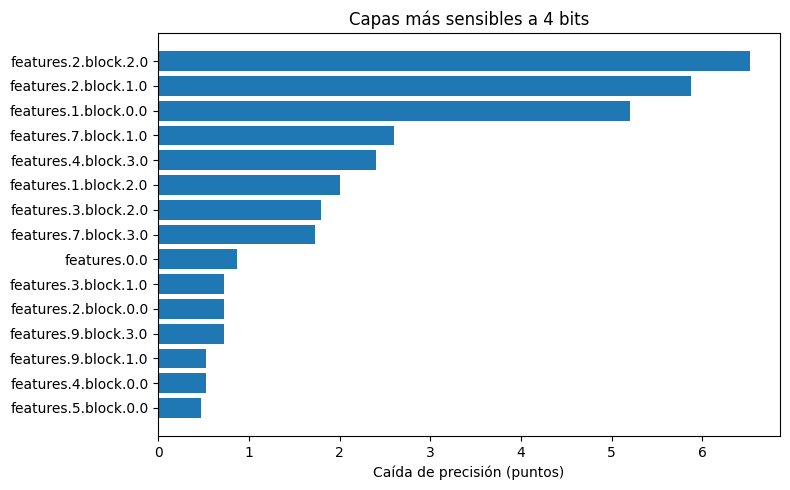

In [21]:
base_acc = accuracy(model, X_search, Y_search)
sens = []
for i in range(L):
    bl = [None] * L
    bl[i] = BITS_FOCUS
    set_weights(bl, [1.0] * L)
    sens.append(base_acc - accuracy(model, X_search, Y_search))
set_weights([None] * L, [1.0] * L)

dfS = pd.DataFrame({"capa": names, "parametros": n_w, "caida_puntos": [round(s * 100, 2) for s in sens]})
dfS = dfS.sort_values("caida_puntos", ascending=False)
print(f"Caída de precisión al bajar UNA capa a {BITS_FOCUS} bits (puntos porcentuales):")
print(dfS.head(15).to_string(index=False))
dfS.to_csv("resultados_faseB_sensibilidad.csv", index=False)

top = dfS.head(15).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["capa"].str[-28:], top["caida_puntos"])
plt.xlabel("Caída de precisión (puntos)")
plt.title(f"Capas más sensibles a {BITS_FOCUS} bits")
plt.tight_layout()
plt.savefig("faseB_sensibilidad.png", dpi=120)
plt.show()

## Fase C · Evolución diferencial sobre los recortes

Todas las capas a `BITS_FOCUS` bits. La evolución diferencial ajusta, **para cada capa, qué fracción del valor máximo se
conserva** (el resto se recorta), buscando la mayor precisión posible. Hay un parámetro continuo por capa, que es un caso
natural para este algoritmo.

In [22]:
from scipy.optimize import differential_evolution

NP = DE_POP_MULT * L
rng = np.random.RandomState(SEED)
init = np.clip(1.0 - np.abs(rng.normal(0, 0.12, (NP, L))), ALPHA_MIN, 1.0)
init[0, :] = 1.0                      # el punto de partida "sin recorte" está en la población
best = {"acc": -1.0}
history = []

def objective(alphas):
    set_weights([BITS_FOCUS] * L, list(alphas))
    acc = accuracy(model, X_search, Y_search)
    if acc > best["acc"]:
        best["acc"] = acc
    return -acc

def cb(xk, convergence=None):
    history.append(best["acc"])
    print(f"Generación {len(history)}/{DE_MAXITER} | mejor precisión en búsqueda: {best['acc']*100:.2f}%")
    return False

t0 = time.time()
res = differential_evolution(objective, bounds=[(ALPHA_MIN, 1.0)] * L, init=init, maxiter=DE_MAXITER,
                             tol=0, polish=False, updating="immediate", seed=SEED, callback=cb)
alphas_de = np.array(res.x)
print(f"Búsqueda terminada en {time.time()-t0:.0f} s")

def final_acc(bits_list, alpha_list):
    set_weights(bits_list, alpha_list)
    a = accuracy(model, X_final, Y_final)
    set_weights([None] * L, [1.0] * L)
    return a

rowsC = [
    {"version": "FP32", "precision_final_pct": round(final_acc([None] * L, [1.0] * L) * 100, 2), "tamano_MB": round(size_mb([None] * L), 2)},
    {"version": f"{BITS_FOCUS} bits, sin recorte (alpha=1)", "precision_final_pct": round(final_acc([BITS_FOCUS] * L, [1.0] * L) * 100, 2), "tamano_MB": round(size_mb([BITS_FOCUS] * L), 2)},
    {"version": f"{BITS_FOCUS} bits, recortes optimizados (DE)", "precision_final_pct": round(final_acc([BITS_FOCUS] * L, list(alphas_de)) * 100, 2), "tamano_MB": round(size_mb([BITS_FOCUS] * L), 2)},
]
dfC = pd.DataFrame(rowsC)
print(dfC.to_string(index=False))
dfC.to_csv("resultados_faseC.csv", index=False)
np.save("alphas_de.npy", alphas_de)

Generación 1/20 | mejor precisión en búsqueda: 45.07%
Generación 2/20 | mejor precisión en búsqueda: 46.53%
Generación 3/20 | mejor precisión en búsqueda: 46.53%
Generación 4/20 | mejor precisión en búsqueda: 46.53%
Generación 5/20 | mejor precisión en búsqueda: 46.53%
Generación 6/20 | mejor precisión en búsqueda: 47.67%
Generación 7/20 | mejor precisión en búsqueda: 48.40%
Generación 8/20 | mejor precisión en búsqueda: 48.40%
Generación 9/20 | mejor precisión en búsqueda: 48.40%
Generación 10/20 | mejor precisión en búsqueda: 48.40%
Generación 11/20 | mejor precisión en búsqueda: 48.40%
Generación 12/20 | mejor precisión en búsqueda: 48.40%
Generación 13/20 | mejor precisión en búsqueda: 53.67%
Generación 14/20 | mejor precisión en búsqueda: 53.67%
Generación 15/20 | mejor precisión en búsqueda: 53.67%
Generación 16/20 | mejor precisión en búsqueda: 54.13%
Generación 17/20 | mejor precisión en búsqueda: 54.13%
Generación 18/20 | mejor precisión en búsqueda: 54.13%
Generación 19/20 | 

## Fase D · Búsqueda multiobjetivo (precisión contra tamaño)

Ahora cada capa puede tener su propio número de bits (3, 4, 6 u 8) y su propio recorte.
Se buscan a la vez **dos objetivos**: más precisión y menos tamaño. El resultado no es una sola solución sino una
**frontera** de soluciones que no se pueden mejorar en un objetivo sin empeorar el otro (la idea de NSGA-II).

In [23]:
def dominates(a, b):
    return (a[0] <= b[0] and a[1] <= b[1]) and (a[0] < b[0] or a[1] < b[1])

def nondominated_sort(F):
    n = len(F)
    S = [[] for _ in range(n)]
    cnt = [0] * n
    fronts = [[]]
    for p in range(n):
        for q in range(n):
            if p == q:
                continue
            if dominates(F[p], F[q]):
                S[p].append(q)
            elif dominates(F[q], F[p]):
                cnt[p] += 1
        if cnt[p] == 0:
            fronts[0].append(p)
    i = 0
    while fronts[i]:
        nxt = []
        for p in fronts[i]:
            for q in S[p]:
                cnt[q] -= 1
                if cnt[q] == 0:
                    nxt.append(q)
        i += 1
        fronts.append(nxt)
    return fronts[:-1]

def crowding(F, front):
    d = {i: 0.0 for i in front}
    for m in range(2):
        order = sorted(front, key=lambda i: F[i][m])
        d[order[0]] = float("inf")
        d[order[-1]] = float("inf")
        span = F[order[-1]][m] - F[order[0]][m]
        if span == 0:
            continue
        for k in range(1, len(order) - 1):
            d[order[k]] += (F[order[k + 1]][m] - F[order[k - 1]][m]) / span
    return d

In [24]:
cache = {}

def evaluate(g):
    bi, al = g
    key = (tuple(int(v) for v in bi), tuple(np.round(al, 3)))
    if key in cache:
        return cache[key]
    bl = [BIT_CHOICES[int(i)] for i in bi]
    set_weights(bl, list(al))
    acc = accuracy(model, X_search, Y_search)
    f = (1.0 - acc, size_mb(bl))          # ambos se minimizan
    cache[key] = f
    return f

def random_genome(rng):
    return (rng.randint(0, len(BIT_CHOICES), L), rng.uniform(0.7, 1.0, L))

def crossover(g1, g2, rng):
    mask = rng.rand(L) < 0.5
    return (np.where(mask, g1[0], g2[0]), np.where(mask, g1[1], g2[1]))

def mutate(g, rng, pm):
    bi, al = g[0].copy(), g[1].copy()
    for i in range(L):
        if rng.rand() < pm:
            bi[i] = int(np.clip(bi[i] + rng.choice([-1, 1]), 0, len(BIT_CHOICES) - 1))
        if rng.rand() < pm:
            al[i] = float(np.clip(al[i] + rng.normal(0, 0.05), ALPHA_MIN, 1.0))
    return (bi, al)

rng = np.random.RandomState(SEED + 1)

# Población inicial: versiones uniformes + la solución de la Fase C + aleatorias
pop = []
for k in range(len(BIT_CHOICES)):
    pop.append((np.full(L, k), np.ones(L)))
if "alphas_de" in globals():
    pop.append((np.full(L, BIT_CHOICES.index(BITS_FOCUS)), np.array(alphas_de)))
while len(pop) < MO_POP:
    pop.append(mutate(pop[rng.randint(0, len(pop))], rng, 0.2) if rng.rand() < 0.5 else random_genome(rng))
pop = pop[:MO_POP]
F = [evaluate(g) for g in pop]

t0 = time.time()
for gen in range(MO_GENS):
    fronts = nondominated_sort(F)
    rank, crowd = {}, {}
    for r, fr in enumerate(fronts):
        d = crowding(F, fr)
        for i in fr:
            rank[i] = r
            crowd[i] = d[i]

    def tournament():
        i, j = rng.randint(0, len(pop), 2)
        if rank[i] != rank[j]:
            return i if rank[i] < rank[j] else j
        return i if crowd[i] >= crowd[j] else j

    children = []
    while len(children) < MO_POP:
        p1, p2 = pop[tournament()], pop[tournament()]
        children.append(mutate(crossover(p1, p2, rng), rng, 2.0 / L))
    Fc = [evaluate(g) for g in children]

    allp, allF = pop + children, F + Fc
    newp, newF = [], []
    for fr in nondominated_sort(allF):
        if len(newp) + len(fr) <= MO_POP:
            sel = fr
        else:
            d = crowding(allF, fr)
            sel = sorted(fr, key=lambda i: -d[i])[:MO_POP - len(newp)]
        for i in sel:
            newp.append(allp[i]); newF.append(allF[i])
        if len(newp) >= MO_POP:
            break
    pop, F = newp, newF
    front0 = nondominated_sort(F)[0]
    best_acc = max(1 - F[i][0] for i in front0)
    print(f"Generación {gen+1}/{MO_GENS} | frontera: {len(front0)} soluciones | mejor precisión (búsqueda): {best_acc*100:.2f}% | {time.time()-t0:.0f} s")
set_weights([None] * L, [1.0] * L)

Generación 1/20 | frontera: 13 soluciones | mejor precisión (búsqueda): 79.87% | 2 s
Generación 2/20 | frontera: 16 soluciones | mejor precisión (búsqueda): 79.87% | 4 s
Generación 3/20 | frontera: 18 soluciones | mejor precisión (búsqueda): 79.87% | 5 s
Generación 4/20 | frontera: 19 soluciones | mejor precisión (búsqueda): 79.87% | 7 s
Generación 5/20 | frontera: 22 soluciones | mejor precisión (búsqueda): 79.87% | 9 s
Generación 6/20 | frontera: 20 soluciones | mejor precisión (búsqueda): 79.87% | 11 s
Generación 7/20 | frontera: 18 soluciones | mejor precisión (búsqueda): 79.87% | 13 s
Generación 8/20 | frontera: 23 soluciones | mejor precisión (búsqueda): 79.87% | 14 s
Generación 9/20 | frontera: 18 soluciones | mejor precisión (búsqueda): 79.87% | 16 s
Generación 10/20 | frontera: 21 soluciones | mejor precisión (búsqueda): 79.87% | 18 s
Generación 11/20 | frontera: 20 soluciones | mejor precisión (búsqueda): 79.87% | 20 s
Generación 12/20 | frontera: 22 soluciones | mejor precis

 tamano_MB  bits_promedio_pesos  precision_busqueda_pct  precision_final_pct
      0.61                 3.00                   10.93                10.69
      0.61                 3.00                   10.93                10.69
      0.61                 3.00                   10.93                10.69
      0.61                 3.00                   10.93                10.69
      0.61                 3.00                   11.07                12.78
      0.61                 3.01                   17.07                18.74
      0.63                 3.10                   17.80                18.35
      0.63                 3.14                   18.20                19.93
      0.63                 3.14                   36.67                38.04
      0.66                 3.26                   41.07                40.49
      0.66                 3.29                   52.13                53.51
      0.67                 3.35                   55.33                57.26

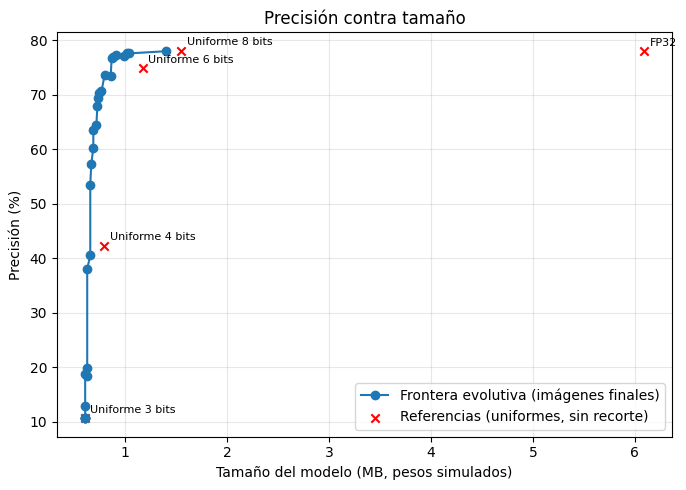

In [25]:
front0 = nondominated_sort(F)[0]
front0 = sorted(front0, key=lambda i: F[i][1])

rowsD = []
for i in front0:
    bi, al = pop[i]
    bl = [BIT_CHOICES[int(k)] for k in bi]
    acc_f = final_acc(bl, list(al))
    avg_bits = sum(nw * b for nw, b in zip(n_w, bl)) / sum(n_w)
    rowsD.append({"tamano_MB": round(size_mb(bl), 2), "bits_promedio_pesos": round(avg_bits, 2),
                  "precision_busqueda_pct": round((1 - F[i][0]) * 100, 2),
                  "precision_final_pct": round(acc_f * 100, 2), "bits_por_capa": bl, "alphas": [round(float(a), 3) for a in al]})
dfD = pd.DataFrame(rowsD)
print(dfD[["tamano_MB", "bits_promedio_pesos", "precision_busqueda_pct", "precision_final_pct"]].to_string(index=False))
dfD.to_json("resultados_faseD_frontera.json", orient="records", force_ascii=False, indent=1)

# Referencias uniformes sobre las mismas imágenes finales
refs = [("FP32", [None] * L)] + [(f"Uniforme {b} bits", [b] * L) for b in (8, 6, 4, 3)]
ref_pts = [(n, size_mb(bl), final_acc(bl, [1.0] * L) * 100) for n, bl in refs]
for n, s, a in ref_pts:
    print(f"{n:>16}: {s:5.2f} MB | {a:5.2f}%")

plt.figure(figsize=(7, 5))
plt.plot(dfD["tamano_MB"], dfD["precision_final_pct"], "o-", label="Frontera evolutiva (imágenes finales)")
plt.scatter([r[1] for r in ref_pts], [r[2] for r in ref_pts], marker="x", color="red", label="Referencias (uniformes, sin recorte)")
for n, s, a in ref_pts:
    plt.annotate(n, (s, a), textcoords="offset points", xytext=(4, 4), fontsize=8)
plt.xlabel("Tamaño del modelo (MB, pesos simulados)")
plt.ylabel("Precisión (%)")
plt.title("Precisión contra tamaño")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("faseD_frontera.png", dpi=130)
plt.show()

## Cómo leer los resultados

1. **Fase A:** dice dónde está el problema (pesos o activaciones).
2. **Fase C:** compara 4 bits **sin recorte** contra 4 bits **con recortes optimizados**. Si la diferencia es grande,
   la optimización evolutiva aporta algo concreto.
3. **Fase D:** la gráfica compara tu frontera con las versiones uniformes. Los puntos de la frontera que quedan
   **arriba y a la izquierda** de los uniformes (más precisión con menos tamaño) son la ganancia de la búsqueda.
4. **Compara siempre con "precisión final"**, medida en imágenes que la búsqueda no usó. Una diferencia grande entre
   "precisión de búsqueda" y "final" indica sobreajuste.

**Límites que debes mencionar en tu caso de portafolio:** es simulación; solo se cuantizan los pesos de convoluciones y
capas lineales; el tamaño cuenta solo esos pesos; la velocidad real no está medida; un conjunto de datos pequeño como
CIFAR-10 no garantiza lo mismo en otros problemas.

Pega en el chat las tablas de las Fases A, C y D. Con eso decidimos el siguiente paso.

# Caso 1 · Paso 4: búsqueda evolutiva sobre las activaciones

**Lo que sabemos.** En el paso 3 vimos que los **pesos** aguantan bien (8 bits casi sin pérdida, y con precisión mixta
por capa la búsqueda evolutiva superó al redondeo uniforme). Lo que rompía la precisión eran las **activaciones**:
con 8 bits y rango MinMax la precisión cayó a ~18%, y con Percentil a ~53%.

**Lo que hace este cuaderno.** Fija los pesos (los de tu frontera del paso 3) y busca, con **evolución diferencial**,
el **rango de recorte de las activaciones de cada capa** (qué valores extremos se descartan antes de pasar a 8 bits).

**Cómo se parametriza.** Para cada capa se calculan, con imágenes de calibración, los rangos que resultan de recortar en
los percentiles 98, 99, 99.5, 99.9, 99.99, 99.999 y 100 (este último es MinMax). La evolución diferencial elige, para cada
capa, un punto continuo entre esos rangos. Son 54 parámetros, uno por capa.

**Importante**
- Es **simulación**, como el paso 3. Solo se cuantizan las *entradas* de las convoluciones y capas lineales; las sumas
  residuales y las multiplicaciones del bloque de squeeze-excitation quedan en decimales. Un circuito real tendría que
  decidir también cómo manejar esas partes.
- Los resultados finales se miden en imágenes que la búsqueda no vio.
- Usa **GPU**. Tiempo estimado: de 20 a 45 minutos.

**Qué necesitas:** `baseline_mobilenetv3s.pt` y, idealmente, `resultados_faseD_frontera.json` del paso 3 (en la misma
sesión de Colab). Si el JSON no está, el cuaderno usa pesos uniformes de 8 y 6 bits.


In [26]:
import os, time, json, random, copy
import numpy as np
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v3_small
from torch.nn.utils.fusion import fuse_conv_bn_eval
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

# ---- Parámetros que puedes ajustar ----
IMG_SIZE = 64
SEARCH_N = 1500            # imágenes que usa la búsqueda
CALIB_N = 500              # imágenes para calcular los rangos candidatos
BITS_ACT = 8               # bits de las activaciones
DE_MAXITER = 25            # generaciones de la evolución diferencial
DE_POP_MULT = 1.5          # individuos = DE_POP_MULT x número de capas
TARGET_SIZES_MB = [1.2, 0.77]   # tamaños de la frontera del paso 3 que se van a probar
MAX_CONFIGS = 3            # cuántas configuraciones de pesos probar (cada una tarda unos 7-15 min)
P_GRID = [98.0, 99.0, 99.5, 99.9, 99.99, 99.999, 100.0]

Dispositivo: cuda


In [27]:
BASE_PT = "baseline_mobilenetv3s.pt"
if not os.path.exists(BASE_PT):
    from google.colab import files
    print("Sube", BASE_PT)
    files.upload()

net = mobilenet_v3_small(weights=None)
net.classifier[3] = nn.Linear(net.classifier[3].in_features, 10)
net.load_state_dict(torch.load(BASE_PT, map_location="cpu"))
net.eval()

def fold_bn(model):
    m = copy.deepcopy(model).eval()
    for module in m.modules():
        keys = list(module._modules.keys())
        for i in range(len(keys) - 1):
            a, b = module._modules[keys[i]], module._modules[keys[i + 1]]
            if isinstance(a, nn.Conv2d) and isinstance(b, nn.BatchNorm2d):
                module._modules[keys[i]] = fuse_conv_bn_eval(a, b)
                module._modules[keys[i + 1]] = nn.Identity()
    return m

model = fold_bn(net).to(device).eval()

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
tf = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.ToTensor(), transforms.Normalize(mean, std)])
test_set = datasets.CIFAR10("./data", train=False, download=True, transform=tf)
loader = torch.utils.data.DataLoader(test_set, batch_size=500, shuffle=False, num_workers=2)
xs, ys = [], []
for x, y in loader:
    xs.append(x); ys.append(y)
X_all = torch.cat(xs).to(device)
Y_all = torch.cat(ys).to(device)

# Misma separación que en el paso 3
X_search, Y_search = X_all[:SEARCH_N], Y_all[:SEARCH_N]
X_final, Y_final = X_all[2000:], Y_all[2000:]
X_calib = X_all[:CALIB_N]

@torch.no_grad()
def accuracy(m, X, Y, bs=500):
    m.eval()
    correct = 0
    for i in range(0, len(X), bs):
        correct += (m(X[i:i + bs]).argmax(1) == Y[i:i + bs]).sum().item()
    return correct / len(X)

acc_fp32 = accuracy(model, X_final, Y_final)
print(f"FP32 con BatchNorm plegada (imágenes finales): {acc_fp32*100:.2f}%  (en el paso 3 salió 77.42%)")

FP32 con BatchNorm plegada (imágenes finales): 77.94%  (en el paso 3 salió 77.42%)


In [28]:
layers = [(n, m) for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
L = len(layers)
names = [n for n, _ in layers]
orig_w = [m.weight.detach().clone() for _, m in layers]
n_w = [w.numel() for w in orig_w]
other_params = sum(p.numel() for p in model.parameters()) - sum(n_w)

def fq_weight(w, bits, alpha):
    qmax = 2 ** (bits - 1) - 1
    flat = w.reshape(w.shape[0], -1)
    maxabs = flat.abs().amax(dim=1, keepdim=True).clamp_min(1e-12)
    scale = (alpha * maxabs) / qmax
    q = torch.clamp(torch.round(flat / scale), -qmax, qmax)
    return (q * scale).reshape_as(w)

@torch.no_grad()
def set_weights(bits_list, alpha_list):
    for (n, m), w0, b, a in zip(layers, orig_w, bits_list, alpha_list):
        m.weight.copy_(w0 if b is None else fq_weight(w0, int(b), float(a)))

def size_mb(bits_list):
    wbits = sum(nw * (32 if b is None else b) for nw, b in zip(n_w, bits_list))
    return (wbits + 32 * other_params) / 8 / 1e6

# ---- Rangos candidatos por capa, calculados con imágenes de calibración (pesos en FP32) ----
K = len(P_GRID)
GRID_IDX = np.arange(K, dtype=float)
IDX_MINMAX = K - 1
IDX_P9999 = P_GRID.index(99.99)
IDX_P999 = P_GRID.index(99.9)

@torch.no_grad()
def collect_tables(X, per_call=400_000):
    store = [[] for _ in range(L)]
    gmin = [float("inf")] * L
    gmax = [float("-inf")] * L
    hs = []
    def mk(i):
        def hook(mod, inp):
            x = inp[0].flatten()
            gmin[i] = min(gmin[i], x.min().item())
            gmax[i] = max(gmax[i], x.max().item())
            stride = max(1, x.numel() // per_call)
            store[i].append(x[::stride].float())
        return hook
    for i, (n, m) in enumerate(layers):
        hs.append(m.register_forward_pre_hook(mk(i)))
    for i in range(0, len(X), 100):
        model(X[i:i + 100])
    for h in hs:
        h.remove()
    q_hi = torch.tensor([p / 100 for p in P_GRID], device=X.device)
    q_lo = torch.tensor([1 - p / 100 for p in P_GRID], device=X.device)
    lo_tab = np.zeros((L, K))
    hi_tab = np.zeros((L, K))
    for i in range(L):
        v = torch.cat(store[i])
        hi_tab[i] = torch.quantile(v, q_hi).cpu().numpy()
        lo_tab[i] = torch.quantile(v, q_lo).cpu().numpy()
        hi_tab[i, -1] = gmax[i]      # el último punto es MinMax real
        lo_tab[i, -1] = gmin[i]
    return lo_tab, hi_tab

set_weights([None] * L, [1.0] * L)
LO_TAB, HI_TAB = collect_tables(X_calib)
print("Tablas de rangos listas:", LO_TAB.shape)

def ranges_from_u(u):
    # u: un valor continuo por capa entre 0 y K-1 (interpola entre los percentiles de la rejilla)
    u = np.clip(np.asarray(u, dtype=float), 0, K - 1)
    lo = np.array([np.interp(u[i], GRID_IDX, LO_TAB[i]) for i in range(L)])
    hi = np.array([np.interp(u[i], GRID_IDX, HI_TAB[i]) for i in range(L)])
    return lo, hi

class ActQuant:
    # Cuantiza la ENTRADA de cada convolución/capa lineal a 'bits' bits (afín, por tensor)
    def __init__(self, bits):
        self.qmax = 2 ** bits - 1
        self.lo = [0.0] * L
        self.scale = [1.0] * L
        self.on = False
        self.handles = [m.register_forward_pre_hook(self._mk(i)) for i, (n, m) in enumerate(layers)]
    def _mk(self, i):
        def hook(mod, inp):
            if not self.on:
                return None
            x = inp[0]
            q = torch.clamp(torch.round((x - self.lo[i]) / self.scale[i]), 0, self.qmax)
            return (q * self.scale[i] + self.lo[i],)
        return hook
    def set_ranges(self, lo, hi):
        self.lo = [float(v) for v in lo]
        self.scale = [max((float(h) - float(l)) / self.qmax, 1e-12) for l, h in zip(lo, hi)]

aq = ActQuant(BITS_ACT)

@torch.no_grad()
def acc_with_u(u, X, Y):
    lo, hi = ranges_from_u(u)
    aq.set_ranges(lo, hi)
    aq.on = True
    a = accuracy(model, X, Y)
    aq.on = False
    return a

Tablas de rangos listas: (54, 7)


In [29]:
# Configuraciones de pesos a probar: uniformes + soluciones de la frontera del paso 3 (si existe el JSON)
FRONT_JSON = "resultados_faseD_frontera.json"
configs = [("Pesos 8 bits uniforme", [8] * L, [1.0] * L)]
if os.path.exists(FRONT_JSON):
    fr = json.load(open(FRONT_JSON))
    for target in TARGET_SIZES_MB:
        best_row = min(fr, key=lambda r: abs(r["tamano_MB"] - target))
        if len(best_row["bits_por_capa"]) == L:
            configs.append((f"Frontera paso 3 (~{best_row['tamano_MB']} MB)", best_row["bits_por_capa"], best_row["alphas"]))
    print("Frontera del paso 3 cargada.")
else:
    print("No encuentro", FRONT_JSON, "-> uso pesos uniformes de 8 y 6 bits.")
    configs.append(("Pesos 6 bits uniforme", [6] * L, [1.0] * L))
configs = configs[:MAX_CONFIGS]
for name, bits, al in configs:
    print(f"  {name}: {size_mb(bits):.2f} MB | bits promedio {sum(a*b for a,b in zip(n_w,bits))/sum(n_w):.2f}")

Frontera del paso 3 cargada.
  Pesos 8 bits uniforme: 1.55 MB | bits promedio 8.00
  Frontera paso 3 (~1.04 MB): 1.04 MB | bits promedio 5.28
  Frontera paso 3 (~0.77 MB): 0.77 MB | bits promedio 3.88


## Comprobación de la simulación

Con pesos de 8 bits y activaciones a 8 bits con rango **MinMax**, debería dar una precisión muy baja (en el paso 3 salió
~18.6%), y con **Percentil 99.99**, de ~53%. Si salen valores parecidos, la simulación de este cuaderno es consistente con la anterior.

In [30]:
set_weights([8] * L, [1.0] * L)
print(f"Solo pesos 8 bits:                 {accuracy(model, X_final, Y_final)*100:.2f}%")
print(f"Pesos 8 + activ. 8, MinMax:        {acc_with_u(np.full(L, IDX_MINMAX), X_final, Y_final)*100:.2f}%   (paso 3: ~18.6%)")
print(f"Pesos 8 + activ. 8, Percentil 99.99: {acc_with_u(np.full(L, IDX_P9999), X_final, Y_final)*100:.2f}%   (paso 3: ~53%)")
set_weights([None] * L, [1.0] * L)

Solo pesos 8 bits:                 78.08%
Pesos 8 + activ. 8, MinMax:        14.64%   (paso 3: ~18.6%)
Pesos 8 + activ. 8, Percentil 99.99: 48.10%   (paso 3: ~53%)


## Búsqueda evolutiva por configuración de pesos

In [31]:
results, recipes = [], []

for name, bits, alphas in configs:
    print(f"\n===== {name} =====")
    set_weights(bits, alphas)
    size = size_mb(bits)
    acc_w = accuracy(model, X_final, Y_final)
    base = {
        "MinMax": acc_with_u(np.full(L, IDX_MINMAX), X_final, Y_final),
        "P99.99": acc_with_u(np.full(L, IDX_P9999), X_final, Y_final),
        "P99.9": acc_with_u(np.full(L, IDX_P999), X_final, Y_final),
    }
    print(f"Tamaño {size:.2f} MB | solo pesos: {acc_w*100:.2f}% | A8 MinMax {base['MinMax']*100:.2f}% | "
          f"P99.99 {base['P99.99']*100:.2f}% | P99.9 {base['P99.9']*100:.2f}%")

    NP = max(8, int(DE_POP_MULT * L))
    rng = np.random.RandomState(SEED)
    init = np.clip(rng.normal(3.5, 1.2, (NP, L)), 0, K - 1)
    init[0, :] = IDX_P9999
    init[1, :] = IDX_P999
    init[2, :] = IDX_MINMAX

    best = {"acc": -1.0}
    gen = [0]
    def objective(u):
        a = acc_with_u(u, X_search, Y_search)
        if a > best["acc"]:
            best["acc"] = a
        return -a
    def cb(xk, convergence=None):
        gen[0] += 1
        if gen[0] % 5 == 0 or gen[0] == 1:
            print(f"  generación {gen[0]}/{DE_MAXITER} | mejor precisión en búsqueda: {best['acc']*100:.2f}%")
        return False

    t0 = time.time()
    res = differential_evolution(objective, bounds=[(0, K - 1)] * L, init=init, maxiter=DE_MAXITER,
                                 tol=0, polish=False, updating="immediate", seed=SEED, callback=cb)
    u_best = np.array(res.x)
    acc_final = acc_with_u(u_best, X_final, Y_final)
    print(f"  Terminado en {time.time()-t0:.0f} s | búsqueda {best['acc']*100:.2f}% | FINAL {acc_final*100:.2f}%")

    lo, hi = ranges_from_u(u_best)
    results.append({"configuracion": name, "tamano_MB_pesos": round(size, 2),
                    "pesos_solo_pct": round(acc_w * 100, 2),
                    "A8_MinMax_pct": round(base["MinMax"] * 100, 2),
                    "A8_P99.99_pct": round(base["P99.99"] * 100, 2),
                    "A8_P99.9_pct": round(base["P99.9"] * 100, 2),
                    "A8_evolutivo_busqueda_pct": round(best["acc"] * 100, 2),
                    "A8_evolutivo_final_pct": round(acc_final * 100, 2)})
    recipes.append({"configuracion": name, "bits_pesos": [int(b) for b in bits], "alphas_pesos": [float(a) for a in alphas],
                    "bits_activaciones": BITS_ACT, "indice_percentil_por_capa": [round(float(v), 3) for v in u_best],
                    "capas": names, "rango_lo": [float(v) for v in lo], "rango_hi": [float(v) for v in hi]})
    set_weights([None] * L, [1.0] * L)

dfR = pd.DataFrame(results)
print(dfR.to_string(index=False))
dfR.to_csv("resultados_paso4.csv", index=False)
json.dump(recipes, open("recetas_activaciones_paso4.json", "w"), indent=1, ensure_ascii=False)
print("\nGuardado: resultados_paso4.csv y recetas_activaciones_paso4.json")


===== Pesos 8 bits uniforme =====
Tamaño 1.55 MB | solo pesos: 78.08% | A8 MinMax 14.64% | P99.99 48.10% | P99.9 72.60%
  generación 1/25 | mejor precisión en búsqueda: 78.27%
  generación 5/25 | mejor precisión en búsqueda: 79.20%
  generación 10/25 | mejor precisión en búsqueda: 79.20%
  generación 15/25 | mejor precisión en búsqueda: 79.20%
  generación 20/25 | mejor precisión en búsqueda: 79.20%
  generación 25/25 | mejor precisión en búsqueda: 79.20%
  Terminado en 162 s | búsqueda 79.20% | FINAL 76.36%

===== Frontera paso 3 (~1.04 MB) =====
Tamaño 1.04 MB | solo pesos: 77.54% | A8 MinMax 17.46% | P99.99 47.09% | P99.9 71.10%
  generación 1/25 | mejor precisión en búsqueda: 77.60%
  generación 5/25 | mejor precisión en búsqueda: 77.93%
  generación 10/25 | mejor precisión en búsqueda: 78.40%
  generación 15/25 | mejor precisión en búsqueda: 78.40%
  generación 20/25 | mejor precisión en búsqueda: 78.47%
  generación 25/25 | mejor precisión en búsqueda: 78.60%
  Terminado en 162 

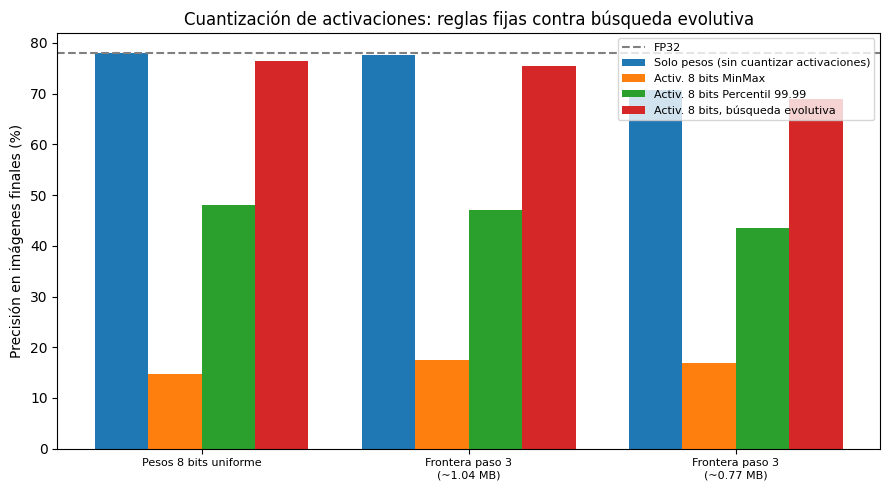

Capas con recorte más agresivo (configuración: Frontera paso 3 (~0.77 MB) )
  features.1.block.1.fc2               índice 0.18  rango [0.00, 0.00]
  features.1.block.0.0                 índice 0.34  rango [-0.35, 5.22]
  features.8.block.2.fc1               índice 0.64  rango [-0.35, 0.99]
  features.5.block.2.fc2               índice 1.27  rango [0.00, 3.09]
  features.5.block.0.0                 índice 1.27  rango [-2.32, 2.36]
  features.5.block.3.0                 índice 1.56  rango [-0.35, 0.53]
  features.11.block.2.fc1              índice 1.82  rango [-0.37, 2.74]
  features.11.block.3.0                índice 1.94  rango [-0.26, 1.44]
  features.2.block.1.0                 índice 2.05  rango [0.00, 4.73]
  features.10.block.1.0                índice 2.34  rango [-0.37, 1.36]


In [32]:
# Gráfica comparativa
labels = dfR["configuracion"].tolist()
cols = [("pesos_solo_pct", "Solo pesos (sin cuantizar activaciones)"), ("A8_MinMax_pct", "Activ. 8 bits MinMax"),
        ("A8_P99.99_pct", "Activ. 8 bits Percentil 99.99"), ("A8_evolutivo_final_pct", "Activ. 8 bits, búsqueda evolutiva")]
x = np.arange(len(labels))
w = 0.2
plt.figure(figsize=(9, 5))
for k, (c, lab) in enumerate(cols):
    plt.bar(x + (k - 1.5) * w, dfR[c], w, label=lab)
plt.axhline(acc_fp32 * 100, color="gray", linestyle="--", label="FP32")
plt.xticks(x, [l.replace(" (", "\n(") for l in labels], fontsize=8)
plt.ylabel("Precisión en imágenes finales (%)")
plt.title("Cuantización de activaciones: reglas fijas contra búsqueda evolutiva")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("paso4_comparacion.png", dpi=130)
plt.show()

# Qué capas recibieron el recorte más agresivo (índice bajo = percentil bajo)
r0 = recipes[-1]
order = np.argsort(r0["indice_percentil_por_capa"])[:10]
print("Capas con recorte más agresivo (configuración:", r0["configuracion"], ")")
for i in order:
    print(f"  {names[i]:<36} índice {r0['indice_percentil_por_capa'][i]:.2f}  rango [{r0['rango_lo'][i]:.2f}, {r0['rango_hi'][i]:.2f}]")

## Cómo leer los resultados

1. **Compara las barras de cada configuración.** Si "búsqueda evolutiva" se acerca a "solo pesos" (y al FP32), las
   activaciones a 8 bits quedan resueltas para esa configuración, y tendrías pesos pequeños más activaciones de 8 bits.
2. **Mira la brecha entre "búsqueda" y "final"** en la tabla. Si es grande, hay sobreajuste a las 1,500 imágenes de búsqueda.
3. **Si no se recupera la precisión,** también es un resultado: indicaría que hacen falta rangos distintos para partes que aquí
   no se cuantizaron (sumas residuales, squeeze-excitation) o entrenar teniendo en cuenta la cuantización.
4. **El archivo `recetas_activaciones_paso4.json`** guarda, capa por capa, los bits de los pesos y el rango de cada
   activación. Es la "receta" que usarías para fijar escalas en un circuito o en un motor de inferencia.

**Límites para tu portafolio:** simulación; solo se cuantizan entradas de convoluciones y capas lineales; no se midió
velocidad; una red y un conjunto de datos; 25 generaciones.

Pega en el chat la tabla de resultados.

# Caso 1 · Paso 5: búsqueda conjunta contra comparaciones fuertes

**Pregunta que responde este cuaderno:** ¿la búsqueda evolutiva conjunta (bits de pesos, bits de activaciones, recorte de
pesos y recorte de activaciones, capa por capa) encuentra mejores soluciones que alternativas razonables con el mismo esfuerzo?

**Tres objetivos a la vez** (todos se minimizan, salvo la precisión, que se maximiza):
1. **Error** (1 − precisión).
2. **Costo de operaciones:** GBOPs = Σ MACs de cada capa × bits de peso × bits de activación (÷10⁹). Es un proxy del área y
   la energía de un multiplicador en un circuito propio.
3. **Memoria de pesos** en MB (pesos a sus bits; los sesgos a 32 bits).

**Qué se compara (todo evaluado en imágenes que ninguna búsqueda vio)**
- **Evolutivo (NSGA-II)**, con 3 semillas aleatorias distintas.
- **Búsqueda aleatoria** con el **mismo número de evaluaciones** y 3 semillas. Si iguala al evolutivo, el mérito no es la evolución.
- **Sensibilidad + asignación voraz:** método clásico de precisión mixta (mide cuánto daña bajar cada capa y baja primero las
  menos sensibles por costo ahorrado).
- **Uniformes con regla fija** (Percentil 99.9) y **uniformes con calibración clásica MSE** (el recorte minimiza el error de
  cuantización, sin mirar la precisión).
- **Recetas del paso 4**, si existen.

**Cómo se mide el éxito.** Para umbrales de precisión (75, 72, 70 y 65%), se reporta el **menor costo (GBOPs) y la menor
memoria** que cada método logra con esa precisión o más, con media ± desviación entre semillas.

**IMPORTANTE: ejecuta primero con `QUICK = True`** (unos 5 minutos) para comprobar que todo corre. Después pon `QUICK = False`.
La corrida completa puede tardar **1 a 2 horas**: no cierres la pestaña. Los resultados parciales se guardan en la carpeta
`resultados_paso5` y, si se corta, al volver a ejecutar se reanuda lo ya terminado (si la sesión de Colab sigue viva;
si quieres que sobrevivan, monta Google Drive y cambia `SAVE_DIR` a una ruta de Drive).

**Límites:** es simulación (solo entradas de convoluciones y capas lineales); no hay entrenamiento consciente de la cuantización;
una red y un conjunto de datos; no se mide velocidad real.

In [57]:
import os, time, json, random, copy
import numpy as np
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v3_small
from torch.nn.utils.fusion import fuse_conv_bn_eval
import pandas as pd
import matplotlib.pyplot as plt

QUICK = False             # True = prueba rápida (~5 min). False = corrida completa (1-2 h)

SEED = 42
IMG_SIZE = 64
SEARCH_N = 1500
CALIB_N = 500
BW_CHOICES = [3, 4, 6, 8]
BA_CHOICES = [4, 6, 8]
P_GRID = [98.0, 99.0, 99.5, 99.9, 99.99, 99.999, 100.0]
TAUS = [75.0, 72.0, 70.0, 65.0]

SEEDS = [0, 1, 2]
POP = 50
GENS = 36
USE_PASO4_SEEDS = False   # True = el evolutivo y el aleatorio parten también de las recetas del paso 4
MAX_FRONT_EVAL = 60
SAVE_DIR = "resultados_paso5"
if QUICK:
    SEEDS, POP, GENS, MAX_FRONT_EVAL = [0], 16, 4, 12
TAG = ("quick" if QUICK else "full") + ("_seeded" if USE_PASO4_SEEDS else "")
os.makedirs(SAVE_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device, "| modo:", TAG, "| evaluaciones por corrida:", POP + GENS * POP)

Dispositivo: cuda | modo: full | evaluaciones por corrida: 1850


In [34]:
BASE_PT = "baseline_mobilenetv3s.pt"
if not os.path.exists(BASE_PT):
    from google.colab import files
    print("Sube", BASE_PT)
    files.upload()

net = mobilenet_v3_small(weights=None)
net.classifier[3] = nn.Linear(net.classifier[3].in_features, 10)
net.load_state_dict(torch.load(BASE_PT, map_location="cpu"))
net.eval()

def fold_bn(model):
    m = copy.deepcopy(model).eval()
    for module in m.modules():
        keys = list(module._modules.keys())
        for i in range(len(keys) - 1):
            a, b = module._modules[keys[i]], module._modules[keys[i + 1]]
            if isinstance(a, nn.Conv2d) and isinstance(b, nn.BatchNorm2d):
                module._modules[keys[i]] = fuse_conv_bn_eval(a, b)
                module._modules[keys[i + 1]] = nn.Identity()
    return m

model = fold_bn(net).to(device).eval()

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
tf = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.ToTensor(), transforms.Normalize(mean, std)])
test_set = datasets.CIFAR10("./data", train=False, download=True, transform=tf)
loader = torch.utils.data.DataLoader(test_set, batch_size=500, shuffle=False, num_workers=2)
xs, ys = [], []
for x, y in loader:
    xs.append(x); ys.append(y)
X_all = torch.cat(xs).to(device)
Y_all = torch.cat(ys).to(device)

# Misma separación que en los pasos 3 y 4: la búsqueda ve las primeras SEARCH_N; el informe usa las 8000 últimas
X_search, Y_search = X_all[:SEARCH_N], Y_all[:SEARCH_N]
X_final, Y_final = X_all[2000:], Y_all[2000:]
X_calib = X_all[:CALIB_N]

@torch.no_grad()
def accuracy(m, X, Y, bs=500):
    m.eval()
    correct = 0
    for i in range(0, len(X), bs):
        correct += (m(X[i:i + bs]).argmax(1) == Y[i:i + bs]).sum().item()
    return correct / len(X)

acc_fp32 = accuracy(model, X_final, Y_final)
print(f"FP32 con BatchNorm plegada (imágenes finales): {acc_fp32*100:.2f}%  (pasos 3 y 4: 77.42%)")

FP32 con BatchNorm plegada (imágenes finales): 77.94%  (pasos 3 y 4: 77.42%)


## Costos y cuantización simulada

In [35]:
layers = [(n, m) for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
L = len(layers)
names = [n for n, _ in layers]
orig_w = [m.weight.detach().clone() for _, m in layers]
n_w = [w.numel() for w in orig_w]
other_params = sum(p.numel() for p in model.parameters()) - sum(n_w)

# ---- MACs por capa ----
macs = [0] * L
def mk_mac_hook(i):
    def hook(mod, inp, out):
        if isinstance(mod, nn.Conv2d):
            kh, kw = mod.kernel_size
            macs[i] = int(out.shape[2] * out.shape[3] * mod.out_channels * (mod.in_channels // mod.groups) * kh * kw)
        else:
            macs[i] = int(mod.in_features * mod.out_features)
    return hook
_hs = [m.register_forward_hook(mk_mac_hook(i)) for i, (n, m) in enumerate(layers)]
with torch.no_grad():
    model(X_all[:1])
for h in _hs:
    h.remove()
print(f"MACs totales por imagen: {sum(macs)/1e6:.2f} millones")

def gbops(bw, ba):
    return sum(mc * w * a for mc, w, a in zip(macs, bw, ba)) / 1e9

def mem_mb(bw):
    return (sum(nw * b for nw, b in zip(n_w, bw)) + 32 * other_params) / 8 / 1e6

print(f"Referencias: FP32 {gbops([32]*L,[32]*L):.2f} GBOPs, {mem_mb([32]*L):.2f} MB | W8A8 {gbops([8]*L,[8]*L):.3f} GBOPs, {mem_mb([8]*L):.2f} MB")

def fq_weight(w, bits, alpha):
    qmax = 2 ** (bits - 1) - 1
    flat = w.reshape(w.shape[0], -1)
    maxabs = flat.abs().amax(dim=1, keepdim=True).clamp_min(1e-12)
    scale = (alpha * maxabs) / qmax
    q = torch.clamp(torch.round(flat / scale), -qmax, qmax)
    return (q * scale).reshape_as(w)

@torch.no_grad()
def set_weights(bits_list, alpha_list):
    for (n, m), w0, b, a in zip(layers, orig_w, bits_list, alpha_list):
        m.weight.copy_(w0 if b is None else fq_weight(w0, int(b), float(a)))

# ---- Rangos candidatos por capa (percentiles) y muestras para el criterio MSE ----
K = len(P_GRID)
GRID_IDX = np.arange(K, dtype=float)
IDX_MINMAX = K - 1
IDX_P9999 = P_GRID.index(99.99)
IDX_P999 = P_GRID.index(99.9)

@torch.no_grad()
def collect_tables(X, per_call=400_000, keep=200_000):
    store = [[] for _ in range(L)]
    gmin = [float("inf")] * L
    gmax = [float("-inf")] * L
    hs = []
    def mk(i):
        def hook(mod, inp):
            x = inp[0].flatten()
            gmin[i] = min(gmin[i], x.min().item())
            gmax[i] = max(gmax[i], x.max().item())
            stride = max(1, x.numel() // per_call)
            store[i].append(x[::stride].float())
        return hook
    for i, (n, m) in enumerate(layers):
        hs.append(m.register_forward_pre_hook(mk(i)))
    for i in range(0, len(X), 100):
        model(X[i:i + 100])
    for h in hs:
        h.remove()
    q_hi = torch.tensor([p / 100 for p in P_GRID], device=X.device)
    q_lo = torch.tensor([1 - p / 100 for p in P_GRID], device=X.device)
    lo_tab, hi_tab, samples = np.zeros((L, K)), np.zeros((L, K)), []
    for i in range(L):
        v = torch.cat(store[i])
        hi_tab[i] = torch.quantile(v, q_hi).cpu().numpy()
        lo_tab[i] = torch.quantile(v, q_lo).cpu().numpy()
        hi_tab[i, -1] = gmax[i]
        lo_tab[i, -1] = gmin[i]
        samples.append(v[::max(1, v.numel() // keep)].clone())
    return lo_tab, hi_tab, samples

set_weights([None] * L, [1.0] * L)
LO_TAB, HI_TAB, SAMPLES = collect_tables(X_calib)

def ranges_from_u(u):
    u = np.clip(np.asarray(u, dtype=float), 0, K - 1)
    lo = np.array([np.interp(u[i], GRID_IDX, LO_TAB[i]) for i in range(L)])
    hi = np.array([np.interp(u[i], GRID_IDX, HI_TAB[i]) for i in range(L)])
    return lo, hi

class ActQuant:
    # Cuantiza la ENTRADA de cada convolución/capa lineal; bits distintos por capa
    def __init__(self):
        self.qmax = [255] * L
        self.lo = [0.0] * L
        self.scale = [1.0] * L
        self.on = False
        self.handles = [m.register_forward_pre_hook(self._mk(i)) for i, (n, m) in enumerate(layers)]
    def _mk(self, i):
        def hook(mod, inp):
            if not self.on:
                return None
            x = inp[0]
            q = torch.clamp(torch.round((x - self.lo[i]) / self.scale[i]), 0, self.qmax[i])
            return (q * self.scale[i] + self.lo[i],)
        return hook
    def set_config(self, bits, lo, hi):
        self.qmax = [2 ** int(b) - 1 for b in bits]
        self.lo = [float(v) for v in lo]
        self.scale = [max((float(h) - float(l)) / q, 1e-12) for l, h, q in zip(lo, hi, self.qmax)]

aq = ActQuant()

@torch.no_grad()
def acc_config(bw, alpha, ba, u, X, Y):
    set_weights(bw, alpha)
    lo, hi = ranges_from_u(u)
    aq.set_config(ba, lo, hi)
    aq.on = True
    a = accuracy(model, X, Y)
    aq.on = False
    return a

# ---- Calibración clásica por error cuadrático medio (MSE), sin mirar la precisión ----
def mse_alpha(w, bits):
    grid = np.linspace(0.5, 1.0, 11)
    errs = [((fq_weight(w, bits, float(a)) - w) ** 2).mean().item() for a in grid]
    return float(grid[int(np.argmin(errs))])

def act_mse_idx(i, bits):
    x = SAMPLES[i]
    qmax = 2 ** bits - 1
    best_k, best_e = 0, float("inf")
    for k in range(K):
        lo, hi = float(LO_TAB[i, k]), float(HI_TAB[i, k])
        scale = max((hi - lo) / qmax, 1e-12)
        q = torch.clamp(torch.round((x - lo) / scale), 0, qmax) * scale + lo
        e = ((q - x) ** 2).mean().item()
        if e < best_e:
            best_e, best_k = e, k
    return float(best_k)

ALPHA_MSE = {b: [mse_alpha(w, b) for w in orig_w] for b in BW_CHOICES}
U_MSE = {b: [act_mse_idx(i, b) for i in range(L)] for b in BA_CHOICES}

def classic_cfg(bw, ba):
    alpha = [ALPHA_MSE[int(b)][i] for i, b in enumerate(bw)]
    u = [U_MSE[int(b)][i] for i, b in enumerate(ba)]
    return alpha, u

print("Tablas de rangos y calibración MSE listas.")

MACs totales por imagen: 5.50 millones
Referencias: FP32 5.63 GBOPs, 6.09 MB | W8A8 0.352 GBOPs, 1.55 MB
Tablas de rangos y calibración MSE listas.


## Comprobación rápida

Debe reproducir lo visto antes: pesos 8 bits + activaciones 8 bits con **Percentil 99.9** daba ~73% en el paso 4.

In [36]:
bw, ba = [8] * L, [8] * L
a1 = acc_config(bw, [1.0] * L, ba, [float(IDX_P999)] * L, X_final, Y_final)
al, u = classic_cfg(bw, ba)
a2 = acc_config(bw, al, ba, u, X_final, Y_final)
print(f"W8A8, Percentil 99.9: {a1*100:.2f}%   (paso 4: 73.12%)")
print(f"W8A8, calibración MSE: {a2*100:.2f}%")
set_weights([None] * L, [1.0] * L)

W8A8, Percentil 99.9: 72.60%   (paso 4: 73.12%)
W8A8, calibración MSE: 15.50%


## Algoritmo multiobjetivo (NSGA-II con 3 objetivos)

In [37]:
def dominates(a, b):
    better = False
    for x, y in zip(a, b):
        if x > y:
            return False
        if x < y:
            better = True
    return better

def nondominated_sort(F):
    n = len(F)
    S = [[] for _ in range(n)]
    cnt = [0] * n
    fronts = [[]]
    for p in range(n):
        for q in range(n):
            if p == q:
                continue
            if dominates(F[p], F[q]):
                S[p].append(q)
            elif dominates(F[q], F[p]):
                cnt[p] += 1
        if cnt[p] == 0:
            fronts[0].append(p)
    i = 0
    while fronts[i]:
        nxt = []
        for p in fronts[i]:
            for q in S[p]:
                cnt[q] -= 1
                if cnt[q] == 0:
                    nxt.append(q)
        i += 1
        fronts.append(nxt)
    return fronts[:-1]

def crowding(F, front):
    d = {i: 0.0 for i in front}
    for m in range(len(F[0])):
        order = sorted(front, key=lambda i: F[i][m])
        d[order[0]] = float("inf")
        d[order[-1]] = float("inf")
        span = F[order[-1]][m] - F[order[0]][m]
        if span == 0:
            continue
        for k in range(1, len(order) - 1):
            d[order[k]] += (F[order[k + 1]][m] - F[order[k - 1]][m]) / span
    return d

def pareto_front(F):
    front = []
    for i in range(len(F)):
        if not any(dominates(F[j], F[i]) for j in range(len(F)) if j != i):
            front.append(i)
    return front

In [38]:
# ---------- Genoma: [bits_peso (índice), bits_activación (índice), recorte_peso, índice_percentil_activación] por capa ----------
def sample_genome(rng):
    bw = rng.choice(len(BW_CHOICES), L, p=[0.10, 0.20, 0.30, 0.40])
    ba = rng.choice(len(BA_CHOICES), L, p=[0.15, 0.35, 0.50])
    al = rng.uniform(0.6, 1.0, L)
    u = np.clip(rng.normal(3.5, 1.0, L), 0, K - 1)
    return [bw, ba, al, u]

def paso4_seed_genomes():
    gs = []
    if USE_PASO4_SEEDS and os.path.exists("recetas_activaciones_paso4.json"):
        for r in json.load(open("recetas_activaciones_paso4.json")):
            if len(r["bits_pesos"]) == L:
                gs.append([np.array([BW_CHOICES.index(int(b)) for b in r["bits_pesos"]]),
                           np.full(L, BA_CHOICES.index(8)),
                           np.array(r["alphas_pesos"], dtype=float),
                           np.array(r["indice_percentil_por_capa"], dtype=float)])
    return gs

def std_seed_genomes():
    gs = []
    for wb in (8, 6, 4):
        for ab in (8, 6):
            gs.append([np.full(L, BW_CHOICES.index(wb)), np.full(L, BA_CHOICES.index(ab)),
                       np.ones(L), np.full(L, float(IDX_P999))])
    return gs + paso4_seed_genomes()     # puntos de partida que reciben tanto el evolutivo como el aleatorio

def crossover(g1, g2, rng):
    mask = rng.rand(L) < 0.5
    return [np.where(mask, g1[k], g2[k]) for k in range(4)]

def mutate(g, rng, pm):
    bw, ba, al, u = [np.array(v).copy() for v in g]
    for i in range(L):
        if rng.rand() < pm:
            bw[i] = int(np.clip(bw[i] + rng.choice([-1, 1]), 0, len(BW_CHOICES) - 1))
        if rng.rand() < pm:
            ba[i] = int(np.clip(ba[i] + rng.choice([-1, 1]), 0, len(BA_CHOICES) - 1))
        if rng.rand() < pm:
            al[i] = float(np.clip(al[i] + rng.normal(0, 0.05), 0.4, 1.0))
        if rng.rand() < pm:
            u[i] = float(np.clip(u[i] + rng.normal(0, 0.4), 0, K - 1))
    return [bw, ba, al, u]

def key_of(g):
    return (tuple(int(v) for v in g[0]), tuple(int(v) for v in g[1]),
            tuple(np.round(g[2], 3)), tuple(np.round(g[3], 3)))

def decode(g):
    bw = [BW_CHOICES[int(i)] for i in g[0]]
    ba = [BA_CHOICES[int(i)] for i in g[1]]
    return bw, ba, [float(a) for a in g[2]], [float(v) for v in g[3]]

def run_search(method, seed):
    # method: 'ea' (evolutivo) o 'rs' (aleatorio con el mismo número de evaluaciones)
    rng = np.random.RandomState(1000 + seed)
    budget = POP + GENS * POP
    archive = {}
    def ev(g):
        k = key_of(g)
        if k not in archive:
            bw, ba, al, u = decode(g)
            acc = acc_config(bw, al, ba, u, X_search, Y_search)
            archive[k] = (g, (1.0 - acc, gbops(bw, ba), mem_mb(bw)))
        return archive[k][1]

    seeds = std_seed_genomes()
    pop = seeds + [sample_genome(rng) for _ in range(max(0, POP - len(seeds)))]
    if method == "rs":
        for g in pop:
            ev(g)
        guard = 0
        while len(archive) < budget and guard < 5 * budget:
            ev(sample_genome(rng)); guard += 1
        return archive

    F = [ev(g) for g in pop]
    t0 = time.time()
    for gen in range(GENS):
        fronts = nondominated_sort(F)
        rank, crowd = {}, {}
        for r, fr in enumerate(fronts):
            d = crowding(F, fr)
            for i in fr:
                rank[i], crowd[i] = r, d[i]
        def tournament():
            i, j = rng.randint(0, len(pop), 2)
            if rank[i] != rank[j]:
                return i if rank[i] < rank[j] else j
            return i if crowd[i] >= crowd[j] else j
        children = []
        while len(children) < POP:
            p1, p2 = pop[tournament()], pop[tournament()]
            children.append(mutate(crossover(p1, p2, rng), rng, 2.0 / L))
        Fc = [ev(g) for g in children]
        allp, allF = pop + children, F + Fc
        newp, newF = [], []
        for fr in nondominated_sort(allF):
            if len(newp) + len(fr) <= POP:
                sel = fr
            else:
                d = crowding(allF, fr)
                sel = sorted(fr, key=lambda i: -d[i])[:POP - len(newp)]
            for i in sel:
                newp.append(allp[i]); newF.append(allF[i])
            if len(newp) >= POP:
                break
        pop, F = newp, newF
        if (gen + 1) % 4 == 0 or gen == 0:
            print(f"    generación {gen+1}/{GENS} | {len(archive)} evaluaciones | {time.time()-t0:.0f} s")
    return archive

def finalize(cands, Fs, max_eval):
    # cands: lista de (bw, ba, alpha, u); Fs: sus objetivos de búsqueda. Devuelve el frente evaluado en imágenes finales.
    front = pareto_front(Fs)
    if len(front) > max_eval:
        d = crowding(Fs, front)
        front = sorted(front, key=lambda i: -d[i])[:max_eval]
    members = []
    for i in front:
        bw, ba, al, u = cands[i]
        acc_f = acc_config(bw, al, ba, u, X_final, Y_final)
        members.append({"bw": [int(b) for b in bw], "ba": [int(b) for b in ba],
                        "alpha": [float(a) for a in al], "u": [float(v) for v in u],
                        "acc_search": float(1.0 - Fs[i][0]), "gbops": float(Fs[i][1]), "mem_mb": float(Fs[i][2]),
                        "acc_final": float(acc_f)})
    return members

def threshold_metrics(members):
    out = {}
    for t in TAUS:
        ok = [m for m in members if m["acc_final"] * 100 >= t]
        out[f"gbops@{t:g}"] = min((m["gbops"] for m in ok), default=float("nan"))
        out[f"mem@{t:g}"] = min((m["mem_mb"] for m in ok), default=float("nan"))
    return out

In [39]:
def p999_cfg(bw, ba):
    return [1.0] * len(bw), [float(IDX_P999)] * len(ba)

def run_greedy(cfg_fn):
    # Sensibilidad por capa + asignación voraz (método clásico de precisión mixta), con calibración MSE
    bw0, ba0 = [8] * L, [8] * L
    al0, u0 = cfg_fn(bw0, ba0)
    base = acc_config(bw0, al0, ba0, u0, X_search, Y_search)
    drop_w = np.zeros((L, len(BW_CHOICES)))     # última columna (8 bits) = 0
    drop_a = np.zeros((L, len(BA_CHOICES)))
    for l in range(L):
        for lev in range(len(BW_CHOICES) - 1):
            bw = list(bw0); bw[l] = BW_CHOICES[lev]
            al, u = cfg_fn(bw, ba0)
            drop_w[l, lev] = max(0.0, base - acc_config(bw, al, ba0, u, X_search, Y_search))
        for lev in range(len(BA_CHOICES) - 1):
            ba = list(ba0); ba[l] = BA_CHOICES[lev]
            al, u = cfg_fn(bw0, ba)
            drop_a[l, lev] = max(0.0, base - acc_config(bw0, al, ba, u, X_search, Y_search))

    ref_g, ref_m = gbops(bw0, ba0), mem_mb(bw0)
    lw = [len(BW_CHOICES) - 1] * L
    la = [len(BA_CHOICES) - 1] * L
    states = [(list(lw), list(la))]
    while True:
        best = None
        for l in range(L):
            if lw[l] > 0:
                cur, new = lw[l], lw[l] - 1
                dg = macs[l] * (BW_CHOICES[cur] - BW_CHOICES[new]) * BA_CHOICES[la[l]] / 1e9
                dm = n_w[l] * (BW_CHOICES[cur] - BW_CHOICES[new]) / 8 / 1e6
                dd = max(0.0, drop_w[l, new] - drop_w[l, cur])
                score = (dg / ref_g + dm / ref_m) / (dd + 1e-3)
                if best is None or score > best[0]:
                    best = (score, l, "w")
            if la[l] > 0:
                cur, new = la[l], la[l] - 1
                dg = macs[l] * BW_CHOICES[lw[l]] * (BA_CHOICES[cur] - BA_CHOICES[new]) / 1e9
                dd = max(0.0, drop_a[l, new] - drop_a[l, cur])
                score = (dg / ref_g) / (dd + 1e-3)
                if best is None or score > best[0]:
                    best = (score, l, "a")
        if best is None:
            break
        _, l, dim = best
        if dim == "w":
            lw[l] -= 1
        else:
            la[l] -= 1
        states.append((list(lw), list(la)))

    cands, Fs = [], []
    for lw_s, la_s in states:
        bw = [BW_CHOICES[i] for i in lw_s]
        ba = [BA_CHOICES[i] for i in la_s]
        al, u = cfg_fn(bw, ba)
        acc = acc_config(bw, al, ba, u, X_search, Y_search)
        cands.append((bw, ba, al, u))
        Fs.append((1.0 - acc, gbops(bw, ba), mem_mb(bw)))
    return cands, Fs

## Ejecución: evolutivo y aleatorio (con reanudación)

In [58]:
runs = {"ea": {}, "rs": {}}
for method in ("ea", "rs"):
    for seed in SEEDS:
        path = f"{SAVE_DIR}/{TAG}_{method}_seed{seed}.json"
        if os.path.exists(path):
            runs[method][seed] = json.load(open(path))
            print(f"[{method} semilla {seed}] cargado de {path}")
            continue
        t0 = time.time()
        print(f"[{method} semilla {seed}] buscando...")
        archive = run_search(method, seed)
        items = list(archive.values())
        cands = [decode(g) for g, f in items]
        Fs = [f for g, f in items]
        members = finalize(cands, Fs, MAX_FRONT_EVAL)
        res = {"members": members, "n_evals": len(archive), "seconds": round(time.time() - t0)}
        json.dump(res, open(path, "w"))
        runs[method][seed] = res
        best_acc = max(m["acc_final"] for m in members)
        print(f"[{method} semilla {seed}] listo en {res['seconds']} s | {len(archive)} evaluaciones | frente: {len(members)} | mejor precisión final {best_acc*100:.2f}%")

[ea semilla 0] cargado de resultados_paso5/full_ea_seed0.json
[ea semilla 1] cargado de resultados_paso5/full_ea_seed1.json
[ea semilla 2] cargado de resultados_paso5/full_ea_seed2.json
[rs semilla 0] cargado de resultados_paso5/full_rs_seed0.json
[rs semilla 1] cargado de resultados_paso5/full_rs_seed1.json
[rs semilla 2] cargado de resultados_paso5/full_rs_seed2.json


## Ejecución: comparaciones clásicas

In [41]:
def eval_member(bw, ba, al, u, name):
    acc_f = acc_config(bw, al, ba, u, X_final, Y_final)
    return {"nombre": name, "bw": [int(b) for b in bw], "ba": [int(b) for b in ba],
            "alpha": [float(a) for a in al], "u": [float(v) for v in u],
            "gbops": float(gbops(bw, ba)), "mem_mb": float(mem_mb(bw)), "acc_final": float(acc_f)}

baselines = {"Uniforme (Percentil 99.9)": [], "Uniforme (calibración MSE)": [], "Recetas del paso 4": []}
for wb in (8, 6, 4):
    for ab in (8, 6):
        bw, ba = [wb] * L, [ab] * L
        baselines["Uniforme (Percentil 99.9)"].append(
            eval_member(bw, ba, [1.0] * L, [float(IDX_P999)] * L, f"W{wb}A{ab}"))
        al, u = classic_cfg(bw, ba)
        baselines["Uniforme (calibración MSE)"].append(eval_member(bw, ba, al, u, f"W{wb}A{ab}"))

REC_JSON = "recetas_activaciones_paso4.json"
if os.path.exists(REC_JSON):
    for r in json.load(open(REC_JSON)):
        if len(r["bits_pesos"]) == L:
            baselines["Recetas del paso 4"].append(
                eval_member(r["bits_pesos"], [8] * L, r["alphas_pesos"], r["indice_percentil_por_capa"], r["configuracion"]))
else:
    print("No encuentro", REC_JSON, "-> se omiten las recetas del paso 4.")

for label, fn in (("Sensibilidad + voraz (Percentil 99.9)", p999_cfg), ("Sensibilidad + voraz (MSE)", classic_cfg)):
    print(label, "...")
    t0 = time.time()
    g_cands, g_Fs = run_greedy(fn)
    g_members = finalize(g_cands, g_Fs, MAX_FRONT_EVAL)
    baselines[label] = [dict(m, nombre="voraz") for m in g_members]
    print(f"  listo en {time.time()-t0:.0f} s | frente: {len(g_members)}")

rows = []
for meth, lst in baselines.items():
    for m in lst:
        rows.append({"metodo": meth, "config": m["nombre"], "GBOPs": round(m["gbops"], 3),
                     "memoria_MB": round(m["mem_mb"], 2), "precision_final_pct": round(m["acc_final"] * 100, 2)})
dfB = pd.DataFrame(rows)
print(dfB[~dfB["metodo"].str.startswith("Sensibilidad")].to_string(index=False))
dfB.to_csv(f"{SAVE_DIR}/{TAG}_comparaciones_clasicas.csv", index=False)

Sensibilidad + voraz (Percentil 99.9) ...
  listo en 70 s | frente: 60
Sensibilidad + voraz (MSE) ...
  listo en 52 s | frente: 17
                    metodo                     config  GBOPs  memoria_MB  precision_final_pct
 Uniforme (Percentil 99.9)                       W8A8  0.352        1.55                72.60
 Uniforme (Percentil 99.9)                       W8A6  0.264        1.55                28.40
 Uniforme (Percentil 99.9)                       W6A8  0.264        1.17                70.62
 Uniforme (Percentil 99.9)                       W6A6  0.198        1.17                25.41
 Uniforme (Percentil 99.9)                       W4A8  0.176        0.80                38.64
 Uniforme (Percentil 99.9)                       W4A6  0.132        0.80                21.05
Uniforme (calibración MSE)                       W8A8  0.352        1.55                15.50
Uniforme (calibración MSE)                       W8A6  0.264        1.55                14.42
Uniforme (calibración M

## Resultados: menor costo con precisión suficiente

In [42]:
def fmt(vals):
    v = np.array([x for x in vals if not np.isnan(x)], dtype=float)
    if len(v) == 0:
        return "no alcanza"
    if len(vals) == 1:
        return f"{v[0]:.3f}"
    return f"{v.mean():.3f} ± {v.std():.3f} ({len(v)}/{len(vals)})"

def collect(method):
    return [threshold_metrics(runs[method][s]["members"]) for s in SEEDS if s in runs[method]]

summary = {"Evolutivo (NSGA-II)": collect("ea"), "Búsqueda aleatoria": collect("rs")}
for meth, lst in baselines.items():
    if lst:                      # omite métodos sin resultados (p. ej. si no existe el JSON del paso 4)
        summary[meth] = [threshold_metrics(lst)]

tabla_g, tabla_m = [], []
for meth, lst in summary.items():
    rg = {"metodo": meth}
    rm = {"metodo": meth}
    for t in TAUS:
        rg[f"precisión ≥ {t:g}%"] = fmt([x[f"gbops@{t:g}"] for x in lst])
        rm[f"precisión ≥ {t:g}%"] = fmt([x[f"mem@{t:g}"] for x in lst])
    tabla_g.append(rg); tabla_m.append(rm)
dfG, dfM = pd.DataFrame(tabla_g), pd.DataFrame(tabla_m)
print("MENOR COSTO DE OPERACIONES (GBOPs) con la precisión indicada o más — media ± desv (semillas que lo logran / total)")
print(dfG.to_string(index=False))
print("\nMENOR MEMORIA DE PESOS (MB) con la precisión indicada o más")
print(dfM.to_string(index=False))
dfG.to_csv(f"{SAVE_DIR}/{TAG}_tabla_gbops.csv", index=False)
dfM.to_csv(f"{SAVE_DIR}/{TAG}_tabla_memoria.csv", index=False)
print(f"\nReferencia: FP32 = {acc_fp32*100:.2f}% | W8A8 = {gbops([8]*L,[8]*L):.3f} GBOPs, {mem_mb([8]*L):.2f} MB")

MENOR COSTO DE OPERACIONES (GBOPs) con la precisión indicada o más — media ± desv (semillas que lo logran / total)
                               metodo precisión ≥ 75%     precisión ≥ 72%     precisión ≥ 70%     precisión ≥ 65%
                  Evolutivo (NSGA-II)      no alcanza 0.216 ± 0.009 (3/3) 0.186 ± 0.005 (3/3) 0.162 ± 0.009 (3/3)
                   Búsqueda aleatoria      no alcanza 0.352 ± 0.000 (3/3) 0.264 ± 0.000 (3/3) 0.264 ± 0.000 (3/3)
            Uniforme (Percentil 99.9)      no alcanza               0.352               0.264               0.264
           Uniforme (calibración MSE)      no alcanza          no alcanza          no alcanza          no alcanza
                   Recetas del paso 4           0.302               0.302               0.302               0.238
Sensibilidad + voraz (Percentil 99.9)      no alcanza               0.321               0.282               0.195
           Sensibilidad + voraz (MSE)      no alcanza          no alcanza          no a

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

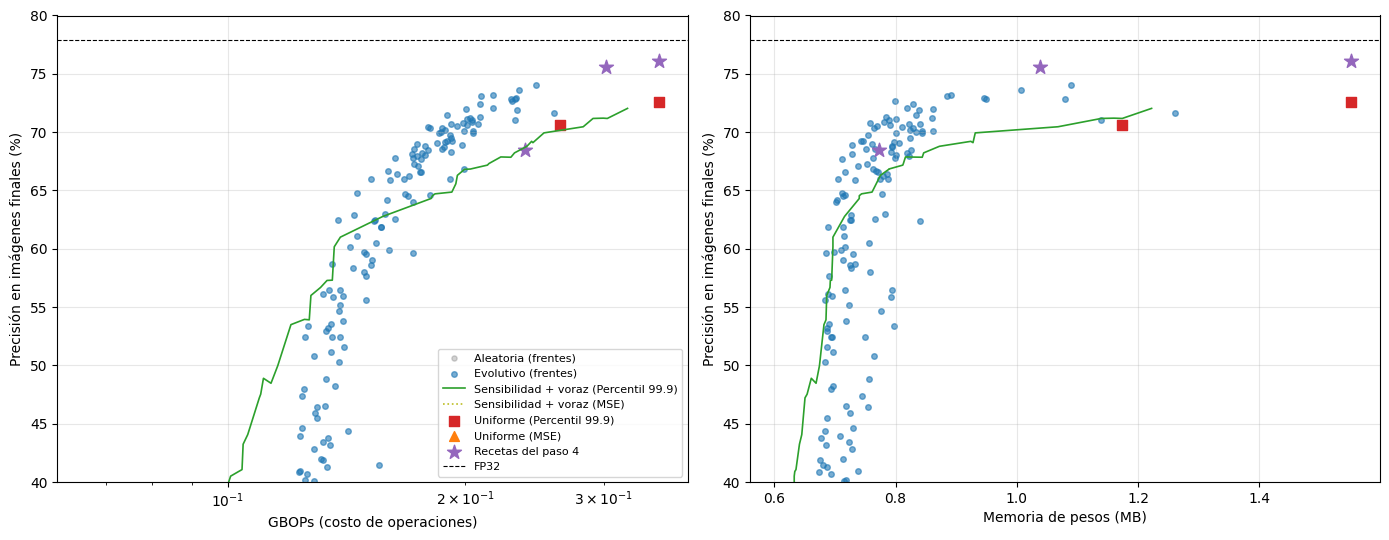

In [43]:
# Gráficas: precisión final contra costo (GBOPs) y contra memoria
def pts(members_list, kx):
    xs = [m[kx] for ms in members_list for m in ms]
    ys = [m["acc_final"] * 100 for ms in members_list for m in ms]
    return xs, ys

ea_lists = [runs["ea"][s]["members"] for s in SEEDS if s in runs["ea"]]
rs_lists = [runs["rs"][s]["members"] for s in SEEDS if s in runs["rs"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, kx, xl in ((axes[0], "gbops", "GBOPs (costo de operaciones)"), (axes[1], "mem_mb", "Memoria de pesos (MB)")):
    x, y = pts(rs_lists, kx); ax.scatter(x, y, s=14, alpha=0.35, label="Aleatoria (frentes)", color="tab:gray")
    x, y = pts(ea_lists, kx); ax.scatter(x, y, s=16, alpha=0.6, label="Evolutivo (frentes)", color="tab:blue")
    for lab, col, ls in (("Sensibilidad + voraz (Percentil 99.9)", "tab:green", "-"), ("Sensibilidad + voraz (MSE)", "tab:olive", ":")):
        x, y = pts([baselines[lab]], kx)
        ax.plot(sorted(x), [v for _, v in sorted(zip(x, y))], ls, lw=1.2, color=col, label=lab)
    x, y = pts([baselines["Uniforme (Percentil 99.9)"]], kx); ax.scatter(x, y, marker="s", s=45, color="tab:red", label="Uniforme (Percentil 99.9)")
    x, y = pts([baselines["Uniforme (calibración MSE)"]], kx); ax.scatter(x, y, marker="^", s=50, color="tab:orange", label="Uniforme (MSE)")
    if baselines["Recetas del paso 4"]:
        x, y = pts([baselines["Recetas del paso 4"]], kx); ax.scatter(x, y, marker="*", s=110, color="tab:purple", label="Recetas del paso 4")
    ax.axhline(acc_fp32 * 100, color="black", linestyle="--", lw=0.8, label="FP32")
    ax.set_xlabel(xl); ax.set_ylabel("Precisión en imágenes finales (%)"); ax.set_ylim(40, 80); ax.grid(alpha=0.3)
axes[0].set_xscale("log")
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/{TAG}_comparacion.png", dpi=130)
plt.show()

In [44]:
# Recetas recomendadas del evolutivo (para fijar bits y rangos en un circuito o motor de inferencia)
pool = [m for s in SEEDS if s in runs["ea"] for m in runs["ea"][s]["members"]]
recs = []
for t in (75.0, 72.0, 70.0):
    ok = [m for m in pool if m["acc_final"] * 100 >= t]
    if ok:
        m = min(ok, key=lambda z: (z["gbops"], z["mem_mb"]))
        lo, hi = ranges_from_u(m["u"])
        recs.append({"criterio": f"menor costo con precisión final >= {t:g}%", "gbops": m["gbops"], "mem_mb": m["mem_mb"],
                     "acc_final": m["acc_final"], "capas": names, "bits_pesos": m["bw"], "bits_activaciones": m["ba"],
                     "alphas_pesos": m["alpha"], "rango_lo": [float(v) for v in lo], "rango_hi": [float(v) for v in hi]})
        print(f"{recs[-1]['criterio']}: {m['gbops']:.3f} GBOPs | {m['mem_mb']:.2f} MB | precisión final {m['acc_final']*100:.2f}% | "
              f"bits de peso promedio {np.average(m['bw'], weights=n_w):.2f}, de activación promedio {np.average(m['ba'], weights=macs):.2f}")
json.dump(recs, open(f"{SAVE_DIR}/{TAG}_recetas_evolutivo.json", "w"), indent=1, ensure_ascii=False)
print("Guardado en", SAVE_DIR)

menor costo con precisión final >= 72%: 0.209 GBOPs | 0.83 MB | precisión final 72.42% | bits de peso promedio 4.17, de activación promedio 6.80
menor costo con precisión final >= 70%: 0.180 GBOPs | 0.81 MB | precisión final 70.43% | bits de peso promedio 4.08, de activación promedio 6.54
Guardado en resultados_paso5


## Cómo interpretar (y qué se puede afirmar)

1. **Evolutivo contra aleatoria (mismo número de evaluaciones).** Mira la tabla de GBOPs y la de memoria. Si el evolutivo
   logra los mismos umbrales con **menos costo**, y la diferencia es mayor que la desviación entre semillas, hay evidencia a
   favor de la búsqueda evolutiva. Si la aleatoria se le acerca o lo iguala, **no** puedes atribuir el mérito a la evolución.
2. **Evolutivo contra sensibilidad + voraz y contra uniformes MSE.** Son los métodos clásicos. Si los iguala, el aporte
   se limita a una alternativa más flexible, no a algo superior.
3. **"no alcanza"** significa que ningún miembro del frente llegó a ese umbral de precisión en las imágenes finales.
4. **Recetas del paso 4:** sirven de referencia. Si el evolutivo conjunto no las supera, la búsqueda conjunta no aporta
   sobre buscar solo los recortes.
5. **Con 3 semillas** las diferencias pequeñas no son concluyentes. Para afirmar algo en un informe, repite con más semillas.

**Límites que debes declarar:** simulación; solo se cuantizan entradas de convoluciones y capas lineales; sin entrenamiento
consciente de la cuantización; una red y un conjunto de datos; sin medición de velocidad ni consumo reales.

Pega en el chat las dos tablas (GBOPs y memoria) y las líneas de recetas recomendadas.

In [45]:
import os, glob, zipfile
from google.colab import files

def carpeta(p):
    n = os.path.basename(p)
    if p.startswith("resultados_paso5"):
        return "paso5"
    if n.startswith(("resultados_paso4", "recetas_activaciones_paso4", "paso4_")):
        return "paso4"
    if n.startswith(("resultados_faseA", "resultados_faseB", "resultados_faseC", "resultados_faseD",
                     "faseB_", "faseD_", "alphas_de")):
        return "paso3"
    if n.startswith(("resultados_paso2", "mobilenetv3s_", "medir_en_pi", "pi_test_")):
        return "paso2"
    if n.startswith(("baseline_", "resultados_linea_base")):
        return "paso1"
    return "otros"

rutas = set(p for p in glob.glob("resultados_paso5/**", recursive=True) if os.path.isfile(p))
for patron in ("*.csv", "*.json", "*.png", "*.pt", "*.onnx", "*.npy", "*.py"):
    rutas |= set(glob.glob(patron))
rutas = sorted(p for p in rutas if not os.path.basename(p).startswith("q_"))   # omite temporales del paso 2b

total = 0
with zipfile.ZipFile("caso1_respaldo.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for p in rutas:
        destino = f"{carpeta(p)}/{os.path.basename(p)}"
        z.write(p, destino)
        total += os.path.getsize(p)
        print(f"{destino:<60} {os.path.getsize(p)/1e6:7.2f} MB")
print(f"\n{len(rutas)} archivos | {total/1e6:.1f} MB sin comprimir")
files.download("caso1_respaldo.zip")

paso3/alphas_de.npy                                             0.00 MB
paso1/baseline_mobilenetv3s.pt                                  6.25 MB
paso3/faseB_sensibilidad.png                                    0.07 MB
paso3/faseD_frontera.png                                        0.05 MB
paso2/mobilenetv3s_dynamic_int8.onnx                            1.70 MB
paso2/mobilenetv3s_fp32.onnx                                    6.12 MB
paso2/mobilenetv3s_prep.onnx                                    6.14 MB
paso2/mobilenetv3s_static_int8.onnx                             1.88 MB
paso4/paso4_comparacion.png                                     0.06 MB
paso2/pi_test_x.npy                                            24.58 MB
paso2/pi_test_y.npy                                             0.00 MB
paso4/recetas_activaciones_paso4.json                           0.02 MB
paso3/resultados_faseA.csv                                      0.00 MB
paso3/resultados_faseB_sensibilidad.csv                         

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Caso 1 · Paso 6: ablación — ¿de dónde viene la ventaja del evolutivo?

**Pregunta.** En el paso 5 la búsqueda conjunta ganó a las alternativas. Pero optimizaba **dos cosas a la vez**:
1. los **bits por capa** (precisión mixta), y
2. los **recortes** de pesos y activaciones.

Los métodos clásicos solo usaban reglas fijas de recorte. Para saber qué parte aporta cada componente, se quita uno a la vez:

| Variante | Bits | Recortes |
|---|---|---|
| **Completa** (la del paso 5) | distintos por capa | optimizados por capa |
| **Solo bits** | distintos por capa | fijos (pesos sin recorte, activaciones Percentil 99.9) |
| **Solo recortes** | iguales en todas las capas | optimizados por capa |

Mismo algoritmo (NSGA-II), mismas semillas, mismo número de evaluaciones, mismos objetivos (error, GBOPs, memoria) y
la misma evaluación final en imágenes que la búsqueda no vio.

**Cómo leer el resultado.** Compara el menor costo que logra cada variante con una precisión dada:
- Si **"solo bits"** pierde mucho contra la completa, los **recortes optimizados** son una parte importante de la ventaja.
- Si **"solo recortes"** pierde mucho, la **precisión mixta por capa** es la parte importante.
- Si ambas pierden, las dos partes aportan.

**Requisitos.** `baseline_mobilenetv3s.pt`, y de preferencia la carpeta `resultados_paso5` del paso 5 en la misma sesión
(si están los archivos `full_ea_seed*.json`, la variante completa no se vuelve a calcular). **Si reentrenaste el modelo base,
borra esos archivos para que no se mezclen familias distintas.**

**Ejecuta primero con `QUICK = True`** (unos 5 minutos) y después con `QUICK = False`: cada variante nueva tarda unos
15 minutos por semilla (de 1 a 1.5 horas en total con 3 semillas; usa `SEEDS = [0, 1]` para acortarlo).
Descarga o copia a Drive la carpeta `resultados_paso5` al terminar.

**Límites:** los mismos del paso 5 (simulación, una red, un conjunto de datos, sin entrenamiento consciente de la cuantización).

In [46]:
import os, time, json, random, copy
import numpy as np
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchvision.models import mobilenet_v3_small
from torch.nn.utils.fusion import fuse_conv_bn_eval
import pandas as pd
import matplotlib.pyplot as plt

QUICK = True             # True = prueba rápida (~5 min). False = corrida completa (1-2 h)

SEED = 42
IMG_SIZE = 64
SEARCH_N = 1500
CALIB_N = 500
BW_CHOICES = [3, 4, 6, 8]
BA_CHOICES = [4, 6, 8]
P_GRID = [98.0, 99.0, 99.5, 99.9, 99.99, 99.999, 100.0]
TAUS = [75.0, 72.0, 70.0, 65.0]

SEEDS = [0, 1, 2]
POP = 50
GENS = 36
USE_PASO4_SEEDS = False   # True = el evolutivo y el aleatorio parten también de las recetas del paso 4
MAX_FRONT_EVAL = 60
SAVE_DIR = "resultados_paso5"
if QUICK:
    SEEDS, POP, GENS, MAX_FRONT_EVAL = [0], 16, 4, 12
TAG = ("quick" if QUICK else "full") + ("_seeded" if USE_PASO4_SEEDS else "")
os.makedirs(SAVE_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device, "| modo:", TAG, "| evaluaciones por corrida:", POP + GENS * POP)

Dispositivo: cuda | modo: quick | evaluaciones por corrida: 80


In [47]:
BASE_PT = "baseline_mobilenetv3s.pt"
if not os.path.exists(BASE_PT):
    from google.colab import files
    print("Sube", BASE_PT)
    files.upload()

net = mobilenet_v3_small(weights=None)
net.classifier[3] = nn.Linear(net.classifier[3].in_features, 10)
net.load_state_dict(torch.load(BASE_PT, map_location="cpu"))
net.eval()

def fold_bn(model):
    m = copy.deepcopy(model).eval()
    for module in m.modules():
        keys = list(module._modules.keys())
        for i in range(len(keys) - 1):
            a, b = module._modules[keys[i]], module._modules[keys[i + 1]]
            if isinstance(a, nn.Conv2d) and isinstance(b, nn.BatchNorm2d):
                module._modules[keys[i]] = fuse_conv_bn_eval(a, b)
                module._modules[keys[i + 1]] = nn.Identity()
    return m

model = fold_bn(net).to(device).eval()

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
tf = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.ToTensor(), transforms.Normalize(mean, std)])
test_set = datasets.CIFAR10("./data", train=False, download=True, transform=tf)
loader = torch.utils.data.DataLoader(test_set, batch_size=500, shuffle=False, num_workers=2)
xs, ys = [], []
for x, y in loader:
    xs.append(x); ys.append(y)
X_all = torch.cat(xs).to(device)
Y_all = torch.cat(ys).to(device)

# Misma separación que en los pasos 3 y 4: la búsqueda ve las primeras SEARCH_N; el informe usa las 8000 últimas
X_search, Y_search = X_all[:SEARCH_N], Y_all[:SEARCH_N]
X_final, Y_final = X_all[2000:], Y_all[2000:]
X_calib = X_all[:CALIB_N]

@torch.no_grad()
def accuracy(m, X, Y, bs=500):
    m.eval()
    correct = 0
    for i in range(0, len(X), bs):
        correct += (m(X[i:i + bs]).argmax(1) == Y[i:i + bs]).sum().item()
    return correct / len(X)

acc_fp32 = accuracy(model, X_final, Y_final)
print(f"FP32 con BatchNorm plegada (imágenes finales): {acc_fp32*100:.2f}%  (pasos 3 y 4: 77.42%)")

FP32 con BatchNorm plegada (imágenes finales): 77.94%  (pasos 3 y 4: 77.42%)


## Costos y cuantización simulada

In [48]:
layers = [(n, m) for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
L = len(layers)
names = [n for n, _ in layers]
orig_w = [m.weight.detach().clone() for _, m in layers]
n_w = [w.numel() for w in orig_w]
other_params = sum(p.numel() for p in model.parameters()) - sum(n_w)

# ---- MACs por capa ----
macs = [0] * L
def mk_mac_hook(i):
    def hook(mod, inp, out):
        if isinstance(mod, nn.Conv2d):
            kh, kw = mod.kernel_size
            macs[i] = int(out.shape[2] * out.shape[3] * mod.out_channels * (mod.in_channels // mod.groups) * kh * kw)
        else:
            macs[i] = int(mod.in_features * mod.out_features)
    return hook
_hs = [m.register_forward_hook(mk_mac_hook(i)) for i, (n, m) in enumerate(layers)]
with torch.no_grad():
    model(X_all[:1])
for h in _hs:
    h.remove()
print(f"MACs totales por imagen: {sum(macs)/1e6:.2f} millones")

def gbops(bw, ba):
    return sum(mc * w * a for mc, w, a in zip(macs, bw, ba)) / 1e9

def mem_mb(bw):
    return (sum(nw * b for nw, b in zip(n_w, bw)) + 32 * other_params) / 8 / 1e6

print(f"Referencias: FP32 {gbops([32]*L,[32]*L):.2f} GBOPs, {mem_mb([32]*L):.2f} MB | W8A8 {gbops([8]*L,[8]*L):.3f} GBOPs, {mem_mb([8]*L):.2f} MB")

def fq_weight(w, bits, alpha):
    qmax = 2 ** (bits - 1) - 1
    flat = w.reshape(w.shape[0], -1)
    maxabs = flat.abs().amax(dim=1, keepdim=True).clamp_min(1e-12)
    scale = (alpha * maxabs) / qmax
    q = torch.clamp(torch.round(flat / scale), -qmax, qmax)
    return (q * scale).reshape_as(w)

@torch.no_grad()
def set_weights(bits_list, alpha_list):
    for (n, m), w0, b, a in zip(layers, orig_w, bits_list, alpha_list):
        m.weight.copy_(w0 if b is None else fq_weight(w0, int(b), float(a)))

# ---- Rangos candidatos por capa (percentiles) y muestras para el criterio MSE ----
K = len(P_GRID)
GRID_IDX = np.arange(K, dtype=float)
IDX_MINMAX = K - 1
IDX_P9999 = P_GRID.index(99.99)
IDX_P999 = P_GRID.index(99.9)

@torch.no_grad()
def collect_tables(X, per_call=400_000, keep=200_000):
    store = [[] for _ in range(L)]
    gmin = [float("inf")] * L
    gmax = [float("-inf")] * L
    hs = []
    def mk(i):
        def hook(mod, inp):
            x = inp[0].flatten()
            gmin[i] = min(gmin[i], x.min().item())
            gmax[i] = max(gmax[i], x.max().item())
            stride = max(1, x.numel() // per_call)
            store[i].append(x[::stride].float())
        return hook
    for i, (n, m) in enumerate(layers):
        hs.append(m.register_forward_pre_hook(mk(i)))
    for i in range(0, len(X), 100):
        model(X[i:i + 100])
    for h in hs:
        h.remove()
    q_hi = torch.tensor([p / 100 for p in P_GRID], device=X.device)
    q_lo = torch.tensor([1 - p / 100 for p in P_GRID], device=X.device)
    lo_tab, hi_tab, samples = np.zeros((L, K)), np.zeros((L, K)), []
    for i in range(L):
        v = torch.cat(store[i])
        hi_tab[i] = torch.quantile(v, q_hi).cpu().numpy()
        lo_tab[i] = torch.quantile(v, q_lo).cpu().numpy()
        hi_tab[i, -1] = gmax[i]
        lo_tab[i, -1] = gmin[i]
        samples.append(v[::max(1, v.numel() // keep)].clone())
    return lo_tab, hi_tab, samples

set_weights([None] * L, [1.0] * L)
LO_TAB, HI_TAB, SAMPLES = collect_tables(X_calib)

def ranges_from_u(u):
    u = np.clip(np.asarray(u, dtype=float), 0, K - 1)
    lo = np.array([np.interp(u[i], GRID_IDX, LO_TAB[i]) for i in range(L)])
    hi = np.array([np.interp(u[i], GRID_IDX, HI_TAB[i]) for i in range(L)])
    return lo, hi

class ActQuant:
    # Cuantiza la ENTRADA de cada convolución/capa lineal; bits distintos por capa
    def __init__(self):
        self.qmax = [255] * L
        self.lo = [0.0] * L
        self.scale = [1.0] * L
        self.on = False
        self.handles = [m.register_forward_pre_hook(self._mk(i)) for i, (n, m) in enumerate(layers)]
    def _mk(self, i):
        def hook(mod, inp):
            if not self.on:
                return None
            x = inp[0]
            q = torch.clamp(torch.round((x - self.lo[i]) / self.scale[i]), 0, self.qmax[i])
            return (q * self.scale[i] + self.lo[i],)
        return hook
    def set_config(self, bits, lo, hi):
        self.qmax = [2 ** int(b) - 1 for b in bits]
        self.lo = [float(v) for v in lo]
        self.scale = [max((float(h) - float(l)) / q, 1e-12) for l, h, q in zip(lo, hi, self.qmax)]

aq = ActQuant()

@torch.no_grad()
def acc_config(bw, alpha, ba, u, X, Y):
    set_weights(bw, alpha)
    lo, hi = ranges_from_u(u)
    aq.set_config(ba, lo, hi)
    aq.on = True
    a = accuracy(model, X, Y)
    aq.on = False
    return a

# ---- Calibración clásica por error cuadrático medio (MSE), sin mirar la precisión ----
def mse_alpha(w, bits):
    grid = np.linspace(0.5, 1.0, 11)
    errs = [((fq_weight(w, bits, float(a)) - w) ** 2).mean().item() for a in grid]
    return float(grid[int(np.argmin(errs))])

def act_mse_idx(i, bits):
    x = SAMPLES[i]
    qmax = 2 ** bits - 1
    best_k, best_e = 0, float("inf")
    for k in range(K):
        lo, hi = float(LO_TAB[i, k]), float(HI_TAB[i, k])
        scale = max((hi - lo) / qmax, 1e-12)
        q = torch.clamp(torch.round((x - lo) / scale), 0, qmax) * scale + lo
        e = ((q - x) ** 2).mean().item()
        if e < best_e:
            best_e, best_k = e, k
    return float(best_k)

ALPHA_MSE = {b: [mse_alpha(w, b) for w in orig_w] for b in BW_CHOICES}
U_MSE = {b: [act_mse_idx(i, b) for i in range(L)] for b in BA_CHOICES}

def classic_cfg(bw, ba):
    alpha = [ALPHA_MSE[int(b)][i] for i, b in enumerate(bw)]
    u = [U_MSE[int(b)][i] for i, b in enumerate(ba)]
    return alpha, u

print("Tablas de rangos y calibración MSE listas.")

MACs totales por imagen: 5.50 millones
Referencias: FP32 5.63 GBOPs, 6.09 MB | W8A8 0.352 GBOPs, 1.55 MB
Tablas de rangos y calibración MSE listas.


## Comprobación rápida

Debe reproducir lo visto antes: pesos 8 bits + activaciones 8 bits con **Percentil 99.9** daba ~73% en el paso 4.

In [49]:
bw, ba = [8] * L, [8] * L
a1 = acc_config(bw, [1.0] * L, ba, [float(IDX_P999)] * L, X_final, Y_final)
al, u = classic_cfg(bw, ba)
a2 = acc_config(bw, al, ba, u, X_final, Y_final)
print(f"W8A8, Percentil 99.9: {a1*100:.2f}%   (paso 4: 73.12%)")
print(f"W8A8, calibración MSE: {a2*100:.2f}%")
set_weights([None] * L, [1.0] * L)

W8A8, Percentil 99.9: 72.60%   (paso 4: 73.12%)
W8A8, calibración MSE: 15.50%


## Algoritmo multiobjetivo (NSGA-II con 3 objetivos)

In [50]:
def dominates(a, b):
    better = False
    for x, y in zip(a, b):
        if x > y:
            return False
        if x < y:
            better = True
    return better

def nondominated_sort(F):
    n = len(F)
    S = [[] for _ in range(n)]
    cnt = [0] * n
    fronts = [[]]
    for p in range(n):
        for q in range(n):
            if p == q:
                continue
            if dominates(F[p], F[q]):
                S[p].append(q)
            elif dominates(F[q], F[p]):
                cnt[p] += 1
        if cnt[p] == 0:
            fronts[0].append(p)
    i = 0
    while fronts[i]:
        nxt = []
        for p in fronts[i]:
            for q in S[p]:
                cnt[q] -= 1
                if cnt[q] == 0:
                    nxt.append(q)
        i += 1
        fronts.append(nxt)
    return fronts[:-1]

def crowding(F, front):
    d = {i: 0.0 for i in front}
    for m in range(len(F[0])):
        order = sorted(front, key=lambda i: F[i][m])
        d[order[0]] = float("inf")
        d[order[-1]] = float("inf")
        span = F[order[-1]][m] - F[order[0]][m]
        if span == 0:
            continue
        for k in range(1, len(order) - 1):
            d[order[k]] += (F[order[k + 1]][m] - F[order[k - 1]][m]) / span
    return d

def pareto_front(F):
    front = []
    for i in range(len(F)):
        if not any(dominates(F[j], F[i]) for j in range(len(F)) if j != i):
            front.append(i)
    return front

In [51]:
# ---------- Genoma: [bits_peso (índice), bits_activación (índice), recorte_peso, índice_percentil_activación] por capa ----------
def sample_genome(rng):
    bw = rng.choice(len(BW_CHOICES), L, p=[0.10, 0.20, 0.30, 0.40])
    ba = rng.choice(len(BA_CHOICES), L, p=[0.15, 0.35, 0.50])
    al = rng.uniform(0.6, 1.0, L)
    u = np.clip(rng.normal(3.5, 1.0, L), 0, K - 1)
    return [bw, ba, al, u]

def paso4_seed_genomes():
    gs = []
    if USE_PASO4_SEEDS and os.path.exists("recetas_activaciones_paso4.json"):
        for r in json.load(open("recetas_activaciones_paso4.json")):
            if len(r["bits_pesos"]) == L:
                gs.append([np.array([BW_CHOICES.index(int(b)) for b in r["bits_pesos"]]),
                           np.full(L, BA_CHOICES.index(8)),
                           np.array(r["alphas_pesos"], dtype=float),
                           np.array(r["indice_percentil_por_capa"], dtype=float)])
    return gs

def std_seed_genomes():
    gs = []
    for wb in (8, 6, 4):
        for ab in (8, 6):
            gs.append([np.full(L, BW_CHOICES.index(wb)), np.full(L, BA_CHOICES.index(ab)),
                       np.ones(L), np.full(L, float(IDX_P999))])
    return gs + paso4_seed_genomes()     # puntos de partida que reciben tanto el evolutivo como el aleatorio

def crossover(g1, g2, rng):
    mask = rng.rand(L) < 0.5
    return [np.where(mask, g1[k], g2[k]) for k in range(4)]

def mutate(g, rng, pm):
    bw, ba, al, u = [np.array(v).copy() for v in g]
    for i in range(L):
        if rng.rand() < pm:
            bw[i] = int(np.clip(bw[i] + rng.choice([-1, 1]), 0, len(BW_CHOICES) - 1))
        if rng.rand() < pm:
            ba[i] = int(np.clip(ba[i] + rng.choice([-1, 1]), 0, len(BA_CHOICES) - 1))
        if rng.rand() < pm:
            al[i] = float(np.clip(al[i] + rng.normal(0, 0.05), 0.4, 1.0))
        if rng.rand() < pm:
            u[i] = float(np.clip(u[i] + rng.normal(0, 0.4), 0, K - 1))
    return [bw, ba, al, u]

def key_of(g):
    return (tuple(int(v) for v in g[0]), tuple(int(v) for v in g[1]),
            tuple(np.round(g[2], 3)), tuple(np.round(g[3], 3)))

def decode(g):
    bw = [BW_CHOICES[int(i)] for i in g[0]]
    ba = [BA_CHOICES[int(i)] for i in g[1]]
    return bw, ba, [float(a) for a in g[2]], [float(v) for v in g[3]]

def project(g, mode):
    # Impone las restricciones de cada variante de la ablación
    bw, ba, al, u = [np.array(v).copy() for v in g]
    if mode == "bits_only":              # recortes fijos
        al = np.ones(L)
        u = np.full(L, float(IDX_P999))
    elif mode == "clip_only":            # bits iguales en todas las capas
        bw = np.full(L, int(np.bincount(bw.astype(int), minlength=len(BW_CHOICES)).argmax()))
        ba = np.full(L, int(np.bincount(ba.astype(int), minlength=len(BA_CHOICES)).argmax()))
    return [bw, ba, al, u]

def mutate_mode(g, rng, pm, mode):
    g2 = mutate(g, rng, pm)
    if mode == "clip_only":              # los bits cambian globalmente, no capa por capa
        b0, a0 = int(g[0][0]), int(g[1][0])
        if rng.rand() < 0.25:
            b0 = int(np.clip(b0 + rng.choice([-1, 1]), 0, len(BW_CHOICES) - 1))
        if rng.rand() < 0.25:
            a0 = int(np.clip(a0 + rng.choice([-1, 1]), 0, len(BA_CHOICES) - 1))
        g2 = [np.full(L, b0), np.full(L, a0), g2[2], g2[3]]
    return project(g2, mode)

def run_search(method, seed, mode="full"):
    # method: 'ea' (evolutivo) o 'rs' (aleatorio con el mismo número de evaluaciones)
    rng = np.random.RandomState(1000 + seed)
    budget = POP + GENS * POP
    archive = {}
    def ev(g):
        k = key_of(g)
        if k not in archive:
            bw, ba, al, u = decode(g)
            acc = acc_config(bw, al, ba, u, X_search, Y_search)
            archive[k] = (g, (1.0 - acc, gbops(bw, ba), mem_mb(bw)))
        return archive[k][1]

    seeds = std_seed_genomes()
    pop = seeds + [sample_genome(rng) for _ in range(max(0, POP - len(seeds)))]
    pop = [project(x, mode) for x in pop]
    if method == "rs":
        for g in pop:
            ev(g)
        guard = 0
        while len(archive) < budget and guard < 5 * budget:
            ev(project(sample_genome(rng), mode)); guard += 1
        return archive

    F = [ev(g) for g in pop]
    t0 = time.time()
    for gen in range(GENS):
        fronts = nondominated_sort(F)
        rank, crowd = {}, {}
        for r, fr in enumerate(fronts):
            d = crowding(F, fr)
            for i in fr:
                rank[i], crowd[i] = r, d[i]
        def tournament():
            i, j = rng.randint(0, len(pop), 2)
            if rank[i] != rank[j]:
                return i if rank[i] < rank[j] else j
            return i if crowd[i] >= crowd[j] else j
        children = []
        while len(children) < POP:
            p1, p2 = pop[tournament()], pop[tournament()]
            children.append(mutate_mode(crossover(p1, p2, rng), rng, 2.0 / L, mode))
        Fc = [ev(g) for g in children]
        allp, allF = pop + children, F + Fc
        newp, newF = [], []
        for fr in nondominated_sort(allF):
            if len(newp) + len(fr) <= POP:
                sel = fr
            else:
                d = crowding(allF, fr)
                sel = sorted(fr, key=lambda i: -d[i])[:POP - len(newp)]
            for i in sel:
                newp.append(allp[i]); newF.append(allF[i])
            if len(newp) >= POP:
                break
        pop, F = newp, newF
        if (gen + 1) % 4 == 0 or gen == 0:
            print(f"    generación {gen+1}/{GENS} | {len(archive)} evaluaciones | {time.time()-t0:.0f} s")
    return archive

def finalize(cands, Fs, max_eval):
    # cands: lista de (bw, ba, alpha, u); Fs: sus objetivos de búsqueda. Devuelve el frente evaluado en imágenes finales.
    front = pareto_front(Fs)
    if len(front) > max_eval:
        d = crowding(Fs, front)
        front = sorted(front, key=lambda i: -d[i])[:max_eval]
    members = []
    for i in front:
        bw, ba, al, u = cands[i]
        acc_f = acc_config(bw, al, ba, u, X_final, Y_final)
        members.append({"bw": [int(b) for b in bw], "ba": [int(b) for b in ba],
                        "alpha": [float(a) for a in al], "u": [float(v) for v in u],
                        "acc_search": float(1.0 - Fs[i][0]), "gbops": float(Fs[i][1]), "mem_mb": float(Fs[i][2]),
                        "acc_final": float(acc_f)})
    return members

def threshold_metrics(members):
    out = {}
    for t in TAUS:
        ok = [m for m in members if m["acc_final"] * 100 >= t]
        out[f"gbops@{t:g}"] = min((m["gbops"] for m in ok), default=float("nan"))
        out[f"mem@{t:g}"] = min((m["mem_mb"] for m in ok), default=float("nan"))
    return out

## Ejecución de las tres variantes (con reanudación)

In [60]:
MODES = ["full", "bits_only", "clip_only"]
NOMBRES = {"full": "Completa (bits + recortes)", "bits_only": "Solo bits (recortes fijos)",
           "clip_only": "Solo recortes (bits iguales)"}

def path_for(mode, seed):
    if mode == "full":        # mismo nombre que en el paso 5, para reutilizar esas corridas
        return f"{SAVE_DIR}/{TAG}_ea_seed{seed}.json"
    return f"{SAVE_DIR}/{TAG}_abl_{mode}_seed{seed}.json"

runs = {m: {} for m in MODES}
for mode in MODES:
    for seed in SEEDS:
        path = path_for(mode, seed)
        if os.path.exists(path):
            runs[mode][seed] = json.load(open(path))
            print(f"[{NOMBRES[mode]} | semilla {seed}] cargado de {path}")
            continue
        t0 = time.time()
        print(f"[{NOMBRES[mode]} | semilla {seed}] buscando...")
        archive = run_search("ea", seed, mode)
        items = list(archive.values())
        cands = [decode(g_) for g_, f in items]
        Fs = [f for g_, f in items]
        members = finalize(cands, Fs, MAX_FRONT_EVAL)
        res = {"members": members, "n_evals": len(archive), "seconds": round(time.time() - t0)}
        json.dump(res, open(path, "w"))
        runs[mode][seed] = res
        best_acc = max(m["acc_final"] for m in members)
        print(f"   listo en {res['seconds']} s | {len(archive)} evaluaciones | frente: {len(members)} | mejor precisión final {best_acc*100:.2f}%")

[Completa (bits + recortes) | semilla 0] cargado de resultados_paso5/full_ea_seed0.json
[Completa (bits + recortes) | semilla 1] cargado de resultados_paso5/full_ea_seed1.json
[Completa (bits + recortes) | semilla 2] cargado de resultados_paso5/full_ea_seed2.json
[Solo bits (recortes fijos) | semilla 0] buscando...
    generación 1/36 | 100 evaluaciones | 4 s
    generación 4/36 | 249 evaluaciones | 16 s
    generación 8/36 | 449 evaluaciones | 33 s
    generación 12/36 | 649 evaluaciones | 50 s
    generación 16/36 | 849 evaluaciones | 67 s
    generación 20/36 | 1047 evaluaciones | 83 s
    generación 24/36 | 1247 evaluaciones | 100 s
    generación 28/36 | 1447 evaluaciones | 117 s
    generación 32/36 | 1647 evaluaciones | 133 s
    generación 36/36 | 1847 evaluaciones | 150 s
   listo en 179 s | 1847 evaluaciones | frente: 60 | mejor precisión final 71.29%
[Solo bits (recortes fijos) | semilla 1] buscando...
    generación 1/36 | 100 evaluaciones | 4 s
    generación 4/36 | 249 ev

## Resultados de la ablación

In [61]:
def eval_member(bw, ba, al, u, name):
    acc_f = acc_config(bw, al, ba, u, X_final, Y_final)
    return {"nombre": name, "bw": [int(b) for b in bw], "ba": [int(b) for b in ba],
            "alpha": [float(a) for a in al], "u": [float(v) for v in u],
            "gbops": float(gbops(bw, ba)), "mem_mb": float(mem_mb(bw)), "acc_final": float(acc_f)}

uniformes = []
for wb in (8, 6, 4):
    for ab in (8, 6):
        uniformes.append(eval_member([wb] * L, [ab] * L, [1.0] * L, [float(IDX_P999)] * L, f"W{wb}A{ab}"))

def fmt(vals):
    v = np.array([x for x in vals if not np.isnan(x)], dtype=float)
    if len(v) == 0:
        return "no alcanza"
    if len(vals) == 1:
        return f"{v[0]:.3f}"
    return f"{v.mean():.3f} ± {v.std():.3f} ({len(v)}/{len(vals)})"

def collect(mode):
    return [threshold_metrics(runs[mode][s]["members"]) for s in SEEDS if s in runs[mode]]

summary = {NOMBRES[m]: collect(m) for m in MODES}
summary["Uniforme (Percentil 99.9)"] = [threshold_metrics(uniformes)]

tabla_g, tabla_m = [], []
for meth, lst in summary.items():
    rg, rm = {"variante": meth}, {"variante": meth}
    for t in TAUS:
        rg[f"precisión ≥ {t:g}%"] = fmt([x[f"gbops@{t:g}"] for x in lst])
        rm[f"precisión ≥ {t:g}%"] = fmt([x[f"mem@{t:g}"] for x in lst])
    tabla_g.append(rg); tabla_m.append(rm)
dfG, dfM = pd.DataFrame(tabla_g), pd.DataFrame(tabla_m)
print("MENOR COSTO DE OPERACIONES (GBOPs) con la precisión indicada o más — media ± desv (semillas que lo logran / total)")
print(dfG.to_string(index=False))
print("\nMENOR MEMORIA DE PESOS (MB) con la precisión indicada o más")
print(dfM.to_string(index=False))
dfG.to_csv(f"{SAVE_DIR}/{TAG}_ablacion_gbops.csv", index=False)
dfM.to_csv(f"{SAVE_DIR}/{TAG}_ablacion_memoria.csv", index=False)

# Costo extra de cada variante respecto a la completa (medias)
print("\nCOSTO EXTRA respecto a la variante completa (menor es mejor; positivo = peor que la completa)")
filas = []
for mode in ("bits_only", "clip_only"):
    fila = {"variante": NOMBRES[mode]}
    for t in TAUS:
        for clave, etiqueta in (("gbops", "GBOPs"), ("mem", "memoria")):
            a = [x[f"{clave}@{t:g}"] for x in summary[NOMBRES["full"]] if not np.isnan(x[f"{clave}@{t:g}"])]
            b = [x[f"{clave}@{t:g}"] for x in summary[NOMBRES[mode]] if not np.isnan(x[f"{clave}@{t:g}"])]
            fila[f"{etiqueta} ≥{t:g}%"] = "—" if (not a or not b) else f"{(np.mean(b) / np.mean(a) - 1) * 100:+.0f}%"
    filas.append(fila)
dfX = pd.DataFrame(filas)
print(dfX.to_string(index=False))
dfX.to_csv(f"{SAVE_DIR}/{TAG}_ablacion_costo_extra.csv", index=False)
print(f"\nReferencia: FP32 = {acc_fp32*100:.2f}% | W8A8 = {gbops([8]*L,[8]*L):.3f} GBOPs, {mem_mb([8]*L):.2f} MB")

MENOR COSTO DE OPERACIONES (GBOPs) con la precisión indicada o más — media ± desv (semillas que lo logran / total)
                    variante     precisión ≥ 75%     precisión ≥ 72%     precisión ≥ 70%     precisión ≥ 65%
  Completa (bits + recortes)          no alcanza 0.216 ± 0.009 (3/3) 0.186 ± 0.005 (3/3) 0.162 ± 0.009 (3/3)
  Solo bits (recortes fijos)          no alcanza          no alcanza 0.206 ± 0.008 (3/3) 0.157 ± 0.007 (3/3)
Solo recortes (bits iguales) 0.323 ± 0.042 (3/3) 0.264 ± 0.000 (3/3) 0.264 ± 0.000 (3/3) 0.264 ± 0.000 (3/3)
   Uniforme (Percentil 99.9)          no alcanza               0.352               0.264               0.264

MENOR MEMORIA DE PESOS (MB) con la precisión indicada o más
                    variante     precisión ≥ 75%     precisión ≥ 72%     precisión ≥ 70%     precisión ≥ 65%
  Completa (bits + recortes)          no alcanza 0.876 ± 0.060 (3/3) 0.773 ± 0.014 (3/3) 0.728 ± 0.025 (3/3)
  Solo bits (recortes fijos)          no alcanza          no 

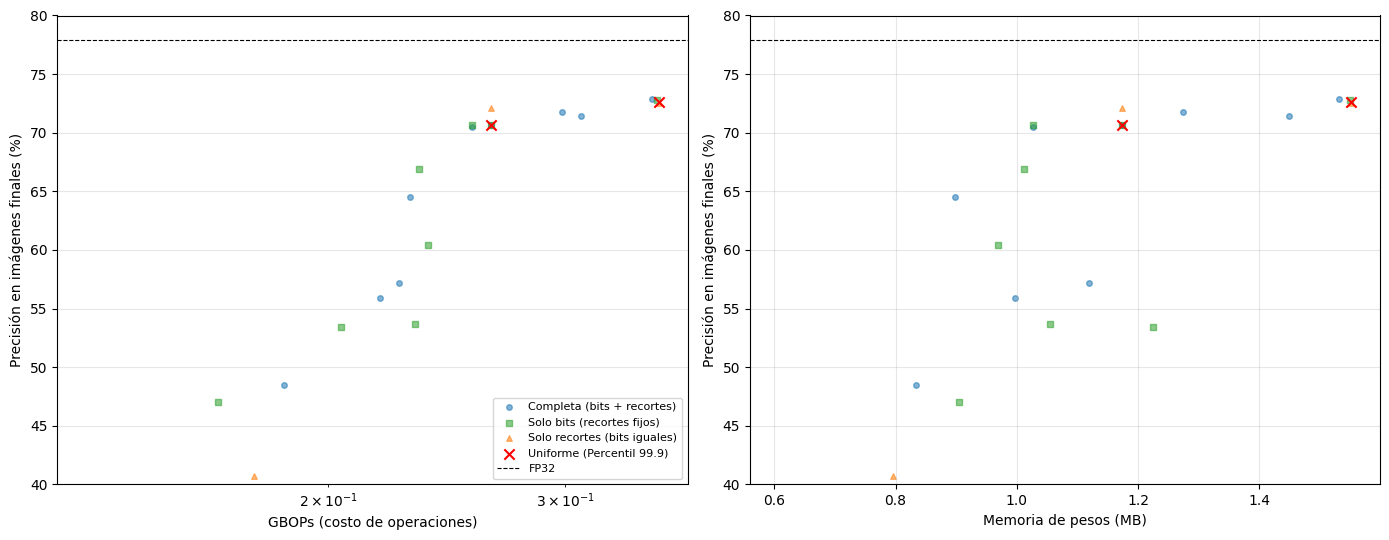

In [55]:
def pts(members_list, kx):
    xs = [m[kx] for ms in members_list for m in ms]
    ys = [m["acc_final"] * 100 for ms in members_list for m in ms]
    return xs, ys

estilos = {"full": ("tab:blue", "o"), "bits_only": ("tab:green", "s"), "clip_only": ("tab:orange", "^")}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, kx, xl in ((axes[0], "gbops", "GBOPs (costo de operaciones)"), (axes[1], "mem_mb", "Memoria de pesos (MB)")):
    for mode in MODES:
        col, mk = estilos[mode]
        x, y = pts([runs[mode][s]["members"] for s in SEEDS if s in runs[mode]], kx)
        ax.scatter(x, y, s=16, alpha=0.55, color=col, marker=mk, label=NOMBRES[mode])
    x, y = pts([uniformes], kx)
    ax.scatter(x, y, marker="x", s=55, color="red", label="Uniforme (Percentil 99.9)")
    ax.axhline(acc_fp32 * 100, color="black", linestyle="--", lw=0.8, label="FP32")
    ax.set_xlabel(xl); ax.set_ylabel("Precisión en imágenes finales (%)"); ax.set_ylim(40, 80); ax.grid(alpha=0.3)
axes[0].set_xscale("log")
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/{TAG}_ablacion.png", dpi=130)
plt.show()

## Cómo interpretar

1. **Mira la tabla de "costo extra".** Un valor como +40% en "Solo bits" con 72% significa que, sin optimizar los recortes, esa
   variante necesita un 40% más de operaciones para la misma precisión: los recortes aportan una parte grande de la ventaja.
2. **Si "solo recortes" tiene costo extra alto,** la precisión mixta por capa es lo importante.
3. **Si las dos variantes quedan cerca de la completa,** la ventaja viene de otra parte (por ejemplo, de la búsqueda misma) y hay
   que mirar con cuidado.
4. **Con 3 semillas,** diferencias menores que la desviación entre semillas (columna "±") no son concluyentes.
5. **Si una variante "no alcanza"** un umbral que otra sí, es una diferencia fuerte.

Pega en el chat las dos tablas y la de costo extra.

In [59]:
import glob
print("QUICK =", QUICK, "| TAG =", TAG, "| SEEDS =", SEEDS, "| POP =", POP, "| GENS =", GENS)
for f in sorted(glob.glob(f"{SAVE_DIR}/*.json")):
    r = json.load(open(f))
    print(f"{os.path.basename(f):<42} {r.get('n_evals')} evaluaciones, {r.get('seconds')} s")

QUICK = False | TAG = full | SEEDS = [0, 1, 2] | POP = 50 | GENS = 36
full_ea_seed0.json                         1850 evaluaciones, 180 s
full_ea_seed1.json                         1850 evaluaciones, 174 s
full_ea_seed2.json                         1850 evaluaciones, 179 s


AttributeError: 'list' object has no attribute 'get'

In [62]:
import os, glob, zipfile
from google.colab import files

def carpeta(p):
    n = os.path.basename(p)
    if p.startswith("resultados_paso5"):
        return "paso5"
    if n.startswith(("resultados_paso4", "recetas_activaciones_paso4", "paso4_")):
        return "paso4"
    if n.startswith(("resultados_faseA", "resultados_faseB", "resultados_faseC", "resultados_faseD",
                     "faseB_", "faseD_", "alphas_de")):
        return "paso3"
    if n.startswith(("resultados_paso2", "mobilenetv3s_", "medir_en_pi", "pi_test_")):
        return "paso2"
    if n.startswith(("baseline_", "resultados_linea_base")):
        return "paso1"
    return "otros"

rutas = set(p for p in glob.glob("resultados_paso5/**", recursive=True) if os.path.isfile(p))
for patron in ("*.csv", "*.json", "*.png", "*.pt", "*.onnx", "*.npy", "*.py"):
    rutas |= set(glob.glob(patron))
rutas = sorted(p for p in rutas if not os.path.basename(p).startswith("q_"))   # omite temporales del paso 2b

total = 0
with zipfile.ZipFile("caso1_respaldo.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for p in rutas:
        destino = f"{carpeta(p)}/{os.path.basename(p)}"
        z.write(p, destino)
        total += os.path.getsize(p)
        print(f"{destino:<60} {os.path.getsize(p)/1e6:7.2f} MB")
print(f"\n{len(rutas)} archivos | {total/1e6:.1f} MB sin comprimir")
files.download("caso1_respaldo.zip")

paso3/alphas_de.npy                                             0.00 MB
paso1/baseline_mobilenetv3s.pt                                  6.25 MB
paso3/faseB_sensibilidad.png                                    0.07 MB
paso3/faseD_frontera.png                                        0.05 MB
paso2/mobilenetv3s_dynamic_int8.onnx                            1.70 MB
paso2/mobilenetv3s_fp32.onnx                                    6.12 MB
paso2/mobilenetv3s_prep.onnx                                    6.14 MB
paso2/mobilenetv3s_static_int8.onnx                             1.88 MB
paso4/paso4_comparacion.png                                     0.06 MB
paso2/pi_test_x.npy                                            24.58 MB
paso2/pi_test_y.npy                                             0.00 MB
paso4/recetas_activaciones_paso4.json                           0.02 MB
paso3/resultados_faseA.csv                                      0.00 MB
paso3/resultados_faseB_sensibilidad.csv                         

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>